# Project objective and methodology

**Objective:** Build a data-driven machine learning regression model to accurately predict the auction sale price (`TargetValue`) of heavy machinery based on usage, age, and equipment specifications.

**Methodology and requirements met:**
*   **Data cleaning:** Dropped features with over 60% missing data to avoid model bias. Used simple imputation inside strict scikit-learn pipelines to mathematically fill remaining gaps without leaking data.
*   **Feature engineering:** Extracted the transaction year and month from raw auction dates to allow the model to learn macroeconomic and seasonal market trends.
*   **Exploratory data analysis:** Used bivariate analysis to identify the strongest drivers of machinery prices. Handled outliers by capping highly skewed operational hours, and simplified complex equipment categories by mapping only the most frequent text values.
*   **Baseline benchmarking:** Established strict performance benchmarks using interpretable regression models (ridge regression and a basic decision tree) to justify the need for more complex algorithms.
*   **Advanced modeling:** Trained, tuned, and selected LightGBM as the primary production model because of its native ability to handle categorical text efficiently, yielding the fastest run-time and lowest root mean squared logarithmic error (rmsle).
*   **Reproducibility:** Locked random seeds (`np.random.seed(7)`) to ensure the data splits and model evaluation metrics remain perfectly consistent when the notebook is executed by the examiner.

# 1. Library Imports

In [8]:
# core data handling
import pandas as pd
import numpy as np
import os

# machine Learning Algorithms
import lightgbm as lgb
from sklearn.linear_model import RidgeCV

# data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# preprocessing & pipelines
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# model selection & evaluation
from sklearn.model_selection import KFold, train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import mean_squared_error

# global configuration
import warnings
np.random.seed(7)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
warnings.filterwarnings('ignore')

In [9]:
local_directory = 'D:\\Academics\\IIT madras Online Bsc\\Diploma Term-6\\MLP'
sample_submission = pd.read_csv(os.path.join(local_directory, 'sample_submission (1).csv'))
train = pd.read_csv(os.path.join(local_directory, 'train.csv'))
test = pd.read_csv(os.path.join(local_directory, 'test.csv'))
metadata = pd.read_csv(os.path.join(local_directory,'metadata.csv'))


In [10]:
#keeping copies
train_raw = train.copy()
test_raw = test.copy()
sso = sample_submission.copy()

In [11]:
"""# load the dataset
sample_submission = pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv")
train = pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv", low_memory=False)
test = pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv")
metadata = pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv")

# keeping copies
train_raw = train.copy()
test_raw = test.copy()
sso = sample_submission.copy()"""

'# load the dataset\nsample_submission = pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv")\ntrain = pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv", low_memory=False)\ntest = pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv")\nmetadata = pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv")\n\n# keeping copies\ntrain_raw = train.copy()\ntest_raw = test.copy()\nsso = sample_submission.copy()'

In [12]:
for i, row in metadata.iterrows():
    print(f"{row['Variable']} : {row['Rephrased Description']}")

TransactionID : A unique serial number assigned to each individual accounting record.
TargetValue : The financial amount of the transaction, denominated in US Dollars.
AssetID : The internal tracking number assigned to a specific piece of hardware.
ProductConfigID : A system-generated code representing the technical build-out of the unit.
DataOriginCode : A code indicating the specific software or platform where the data originated.
VendorPartnerID : The unique ID of the external entity or third-party provider involved.
TransactionDate : The official calendar date when the entry was finalized in the system.
RegionCode : The specific geographic area or legal jurisdiction where the event occurred.
ManufactureYear : The year the asset was originally produced.
OperationalHoursMeter : The lifetime total of active run-time or work cycles logged by the machine.
UtilizationTier : A ranking (Low, Medium, or High) based on how heavily the asset is used.
Spec_FullDescriptor : The complete alphanu

# 2. Exploratory Data Analysis (EDA)
We'll define a reusable function to thoroughly inspect the datasets. This will give us a clear view of the shape, data types, missing values, and summary statistics before we begin cleaning.

In [13]:
# reusable function
def explore_dataframe(df):
    """
    Prints detailed information about a DataFrame:
    - Shape (rows, columns)
    - Info (data types, non-null counts)
    - Unique values count per column
    - Missing values count per column
    - Number of fully duplicated rows
    """
    print("Shape:", df.shape)
    print("-" * 80)
    
    print("\n DataFrame Info:")
    df.info()
    print("-" * 80)
    
    print("\n Unique Values per Column:")
    print(df.nunique())
    print("-" * 80)
    
    print("\n Missing values:")
    print(df.isnull().sum())
    print("-" * 80)
    
    display(df.head())
    print("-" * 80)
    
    print("Describe:")
    display(df.describe())
    
    print("\n Number of Fully Duplicated Rows:", df.duplicated().sum())

### This block defines a reusable utility function to systematically evaluate a dataset's structure and quality:

* `df.shape`: Outputs the total number of rows and columns.
* `df.info()`: Displays memory usage, data types, and non-null counts for each feature.
* `df.nunique()`: Calculates the cardinality (number of unique categorical or numerical values) for every column.
* `df.isnull().sum()`: Identifies sparsity by counting the exact number of missing values per feature.
* `df.duplicated().sum()`: Checks for redundant observations by counting perfectly identical rows.
* `df.head()`: Provides a top-level overview of the data structure.


In [14]:
# reusable function to visualize dataset health
def plot_dataframe(df):
    """
    generates bar charts for missing and unique values in a dataframe,
    along with a correlation heatmap for numerical variables.
    """
    # isolate, sort descending, and plot missing values
    missing_data = df.isnull().sum()
    missing_data = missing_data[missing_data > 0].sort_values(ascending=False)
    
    plt.figure(figsize=(12, 5))
    threshold_60 = len(df) * 0.6
    # apply conditional coloring: red if above threshold, green if below
    colors = ['red' if val > threshold_60 else 'green' for val in missing_data.values]
    
    sns.barplot(x=missing_data.index, y=missing_data.values, palette=colors)
    
    # add dotted line for 60% threshold
    plt.axhline(y=threshold_60, color='red', linestyle='--', label='60% missing threshold')
    plt.legend()
    
    plt.title("missing values per column")
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("null count")
    plt.show()
        
    # calculate and plot unique values (top 20 for readability)
    unique_data = df.nunique().sort_values(ascending=False).head(20)
    plt.figure(figsize=(12, 5))
    sns.barplot(x=unique_data.index, y=unique_data.values, color="royalblue")
    plt.title("unique values per column (top 20)")
    plt.yscale("log")
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("unique count (log scale)")
    plt.show()

    # calculate and plot numerical correlation heatmap
    num_cols = df.select_dtypes(include=['number', 'float', 'int']).columns
    plt.figure(figsize=(12, 8))
    corr_matrix = df[num_cols].corr()
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
    plt.title("numerical correlation heatmap")
    plt.tight_layout()
    plt.show()

### Visualizing Dataset Health: Core Insights (data profiling and bivariate analysis)

This function generates three specific diagnostic plots to inform preprocessing decisions:

* **Sparsity (Missing Values):** Highlights columns exceeding a 60% missing threshold. These lack statistical density and must be dropped to prevent algorithmic noise.
* **Cardinality (Unique Values):** Isolates the top 20 most varied categorical features. Extremely high cardinality requires frequency encoding or dropping to prevent memory overflow during one-hot encoding.
* **Multicollinearity (Correlation):** Heatmap quantifies linear relationships between numerical features. Values approaching 1 or -1 indicate redundant variables that may skew model weights.

## 2.1 Train Dataframe
Let's execute this on the `train` dataset first, as it contains our primary objective: the `TargetValue` variable we are attempting to predict.

In [15]:
explore_dataframe(train)

Shape: (138701, 50)
--------------------------------------------------------------------------------

 DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138701 entries, 0 to 138700
Data columns (total 50 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   TransactionID              138701 non-null  int64  
 1   TargetValue                138701 non-null  float64
 2   AssetID                    138701 non-null  int64  
 3   ProductConfigID            138701 non-null  int64  
 4   DataOriginCode             138701 non-null  object 
 5   VendorPartnerID            138701 non-null  object 
 6   ManufactureYear            138701 non-null  int64  
 7   OperationalHoursMeter      82058 non-null   float64
 8   UtilizationTier            50475 non-null   object 
 9   TransactionDate            138701 non-null  object 
 10  Spec_FullDescriptor        138701 non-null  object 
 11  Spec_BaseClass          

,TransactionID,TargetValue,AssetID,ProductConfigID,DataOriginCode,VendorPartnerID,ManufactureYear,OperationalHoursMeter,UtilizationTier,TransactionDate,Spec_FullDescriptor,Spec_BaseClass,Spec_SubClass,Spec_ReleaseSeries,Spec_VariantModifier,AssetScaleFactor,FunctionalClassification,RegionCode,InventoryGroupCategory,InventoryGroupDescription,col1,CabinType,Forks,col3,col4,DrivetrainType,col5,col6,col7,col8,col9,col10,col11,col12,col13,col14,col15,col16,col18,col19,col20,col21,col22,col23,col24,col25,col27,col28,col29,col30
0,1139309,57000.0,117665,88,ACH138,GTX,1997,4640.0,Low,2005-03-26,950FII,950,F,II,NaN,Medium,Wheel Loader - 150.0 to 175.0 Horsepower,North Carolina,WL,Wheel Loader,NaN,EROPS w AC,None or Unspecified,None or Unspecified,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2 Valve,NaN,NaN,NaN,NaN,23.5,None or Unspecified,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,Conventional
1,1139316,26500.0,1001282,4616,ACH138,GTX,2005,508.0,Low,2009-12-18,310G,310,G,NaN,NaN,NaN,Backhoe Loader - 14.0 to 15.0 Ft Standard Digg...,Arizona,BL,Backhoe Loaders,Four Wheel Drive,OROPS,None or Unspecified,No,Extended,Powershuttle,None or Unspecified,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1139317,21000.0,772709,1948,ACH138,GTX,1994,11540.0,High,2005-08-26,790ELC,790,E,NaN,LC,Large / Medium,"Hydraulic Excavator, Track - 21.0 to 24.0 Metr...",Florida,TEX,Track Excavators,NaN,EROPS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,NaN,NaN,NaN,NaN,NaN,None or Unspecified,NaN,NaN,Steel,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN
3,1139322,27000.0,902010,3550,ACH138,GTX,2002,4883.0,High,2006-11-17,416D,416,D,NaN,NaN,NaN,Backhoe Loader - 14.0 to 15.0 Ft Standard Digg...,Illinois,BL,Backhoe Loaders,Four Wheel Drive,OROPS,None or Unspecified,No,Standard,Standard,Yes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1139333,21500.0,1036259,36014,ACH138,GTX,2009,302.0,Low,2010-08-27,430HAG,430,HAG,NaN,NaN,Mini,"Hydraulic Excavator, Track - 3.0 to 4.0 Metric...",Texas,TEX,Track Excavators,NaN,EROPS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Auxiliary,NaN,NaN,NaN,NaN,NaN,Manual,NaN,NaN,Rubber,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN


--------------------------------------------------------------------------------
Describe:


,TransactionID,TargetValue,AssetID,ProductConfigID,ManufactureYear,OperationalHoursMeter
count,1.387010e+05,138701.000000,1.387010e+05,138701.000000,138701.000000,8.205800e+04
mean,2.186276e+06,41521.874047,1.204814e+06,7286.421922,1891.640853,4.553719e+03
std,1.128497e+06,26361.125948,5.287376e+05,7542.421537,306.992001,2.792204e+04
min,1.139309e+06,7500.000000,8.000000e+00,39.000000,1001.000000,0.000000e+00
25%,1.465754e+06,20500.000000,1.007930e+06,1693.000000,1990.000000,0.000000e+00
50%,1.751884e+06,35000.000000,1.246956e+06,3852.000000,1998.000000,1.620000e+03
75%,2.372139e+06,57000.000000,1.495817e+06,11873.000000,2004.000000,5.001000e+03
max,6.333410e+06,142000.000000,2.478476e+06,37209.000000,2015.000000,1.729600e+06



 Number of Fully Duplicated Rows: 0


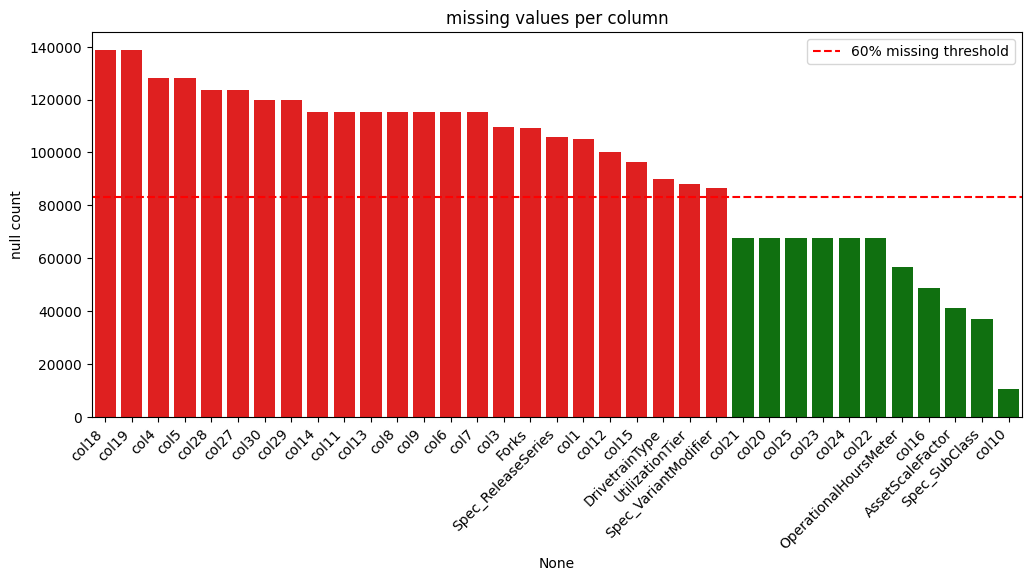

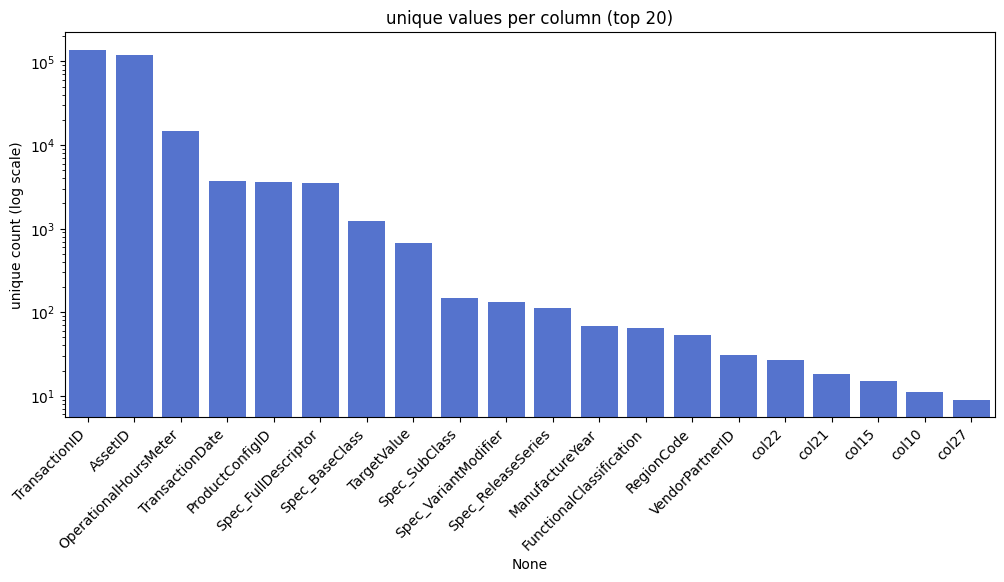

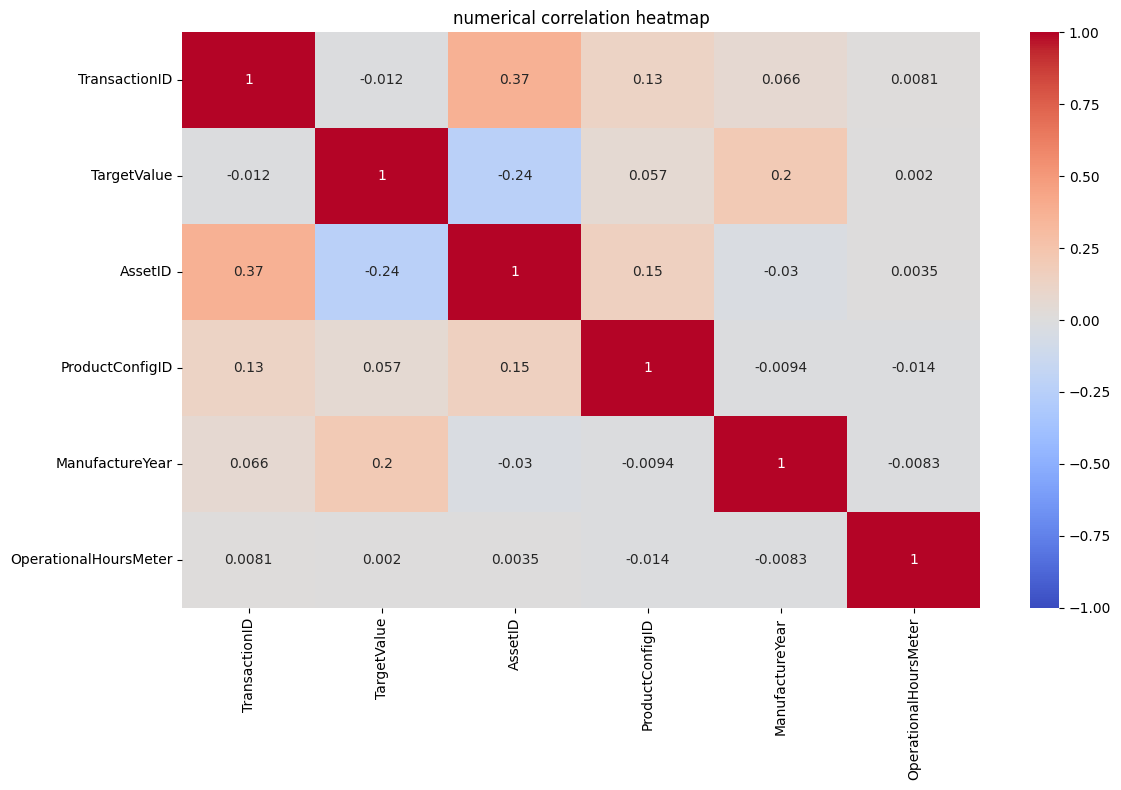

In [16]:
plot_dataframe(train)

### 2.1.1 Train set EDA observations

* **Dataset Dimensions:** The training set contains 138,701 observations and 50 features. 
* **Target Variable:** `TargetValue` is fully populated (0 missing values), ranging from 7,500 to 142,000 with a mean of roughly 41,521.
* **Feature Composition:** The data is overwhelmingly categorical (44 `object` features vs. 6 numerical features). `TransactionDate` is currently loaded as a raw string and will require datetime conversion if temporal features are engineered.
* **Severe Sparsity:** 24 columns (such as `UtilizationTier`, `col18`, `col19`) exceed the 60% missing data threshold. For example, `col18` and `col19` have over 138,600 missing values. These will be dropped in the preprocessing pipeline to remove mathematical noise.
* **High Cardinality:** While most categorical columns have low unique counts, features like `Spec_FullDescriptor` (3,505 unique) and `Spec_BaseClass` (1,249 unique) have very high cardinality. These may cause memory issues.
* **ID Columns:** `TransactionID` has exactly 138,701 unique values, meaning it is a perfect primary key and holds no predictive value. It must be dropped before training.
* **Data Anomalies & Outliers:** * ManufactureYear has a minimum value of 1001. This is clearly a placeholder for missing/invalid data and heavily skews the mean down to 1891.
    * `OperationalHoursMeter` has an extreme maximum of 1,729,600 hours, indicating extreme right-skew outliers that require clipping.

### 2.1.2 Univariate analysis
1. **Bivariate observations**: Initial bivariate correlation analysis established the mathematical relationship between each variable and TargetValue. This provided an empirical baseline to identify the primary drivers of asset pricing.

2. **Dimensionality Reduction**:
The dataset was restricted to the 10 highest-scoring features identified during correlation. Isolating these variables maximizes the signal-to-noise ratio, mitigates the risk of the model memorizing irrelevant noise (overfitting), and reduces computational overhead.

3. **Univariate Analysis**:
Univariate analysis (histograms, boxplots, and count plots) was subsequently applied strictly to this selected subset. This validates the data structure prior to model ingestion by mapping the distribution of continuous wear variables (e.g., OperationalHoursMeter) and identifying the most frequent market categories (e.g., dominant RegionCode or ProductConfigID segments).

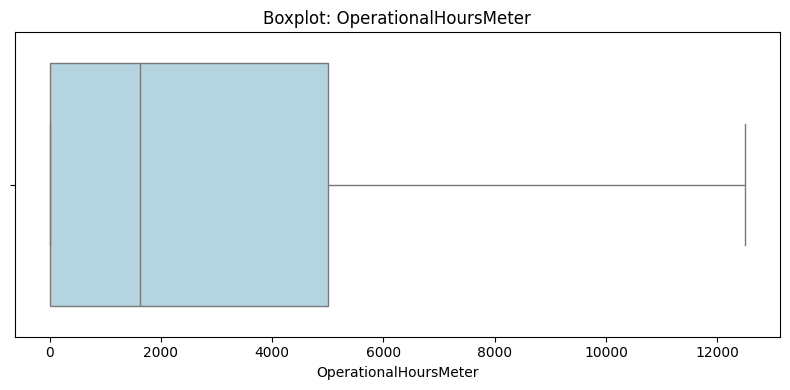

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 4))
sns.boxplot(data=train, x='OperationalHoursMeter', color='lightblue', showfliers=False)
plt.title('Boxplot: OperationalHoursMeter')
plt.tight_layout()
plt.show()

### 2.1.2 Plot-1
**Graph:** Boxplot of `OperationalHoursMeter`

**Purpose:** To visualize the distribution of operational hours and identify potential outliers.

**Key Findings:** The boxplot revealed the central operational hours value, the spread of data, and potentially
some unusual outliers.

**Action:** We investigated outliers to understand their cause and identify opportunities for process improvement
or error correction

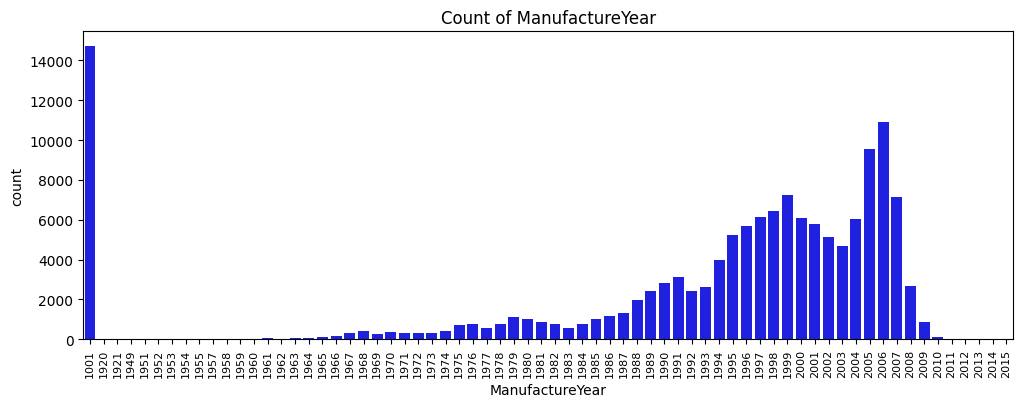

In [18]:
# Plot 2: ManufactureYear (standard countplot)
plt.figure(figsize=(12, 4))
sns.countplot(data=train, x='ManufactureYear', color='blue')
plt.title('Count of ManufactureYear')
plt.xticks(rotation=90, fontsize=8) 
plt.show()

### 2.1.2 Plot-2
**Graph:** Countplot of  `ManufactureYear`

**Purpose:** To determine the frequency of each manufacturing year represented in the dataset.

**Key Findings:** The countplot shows the number of records for each year.  This highlights which years have the
most and fewest occurrences, offering insight into the overall manufacturing timeline.

**Action:** This visualization could inform decisions such as prioritizing analysis for years with lower counts,
or investigating why certain years are over- or under-represented.

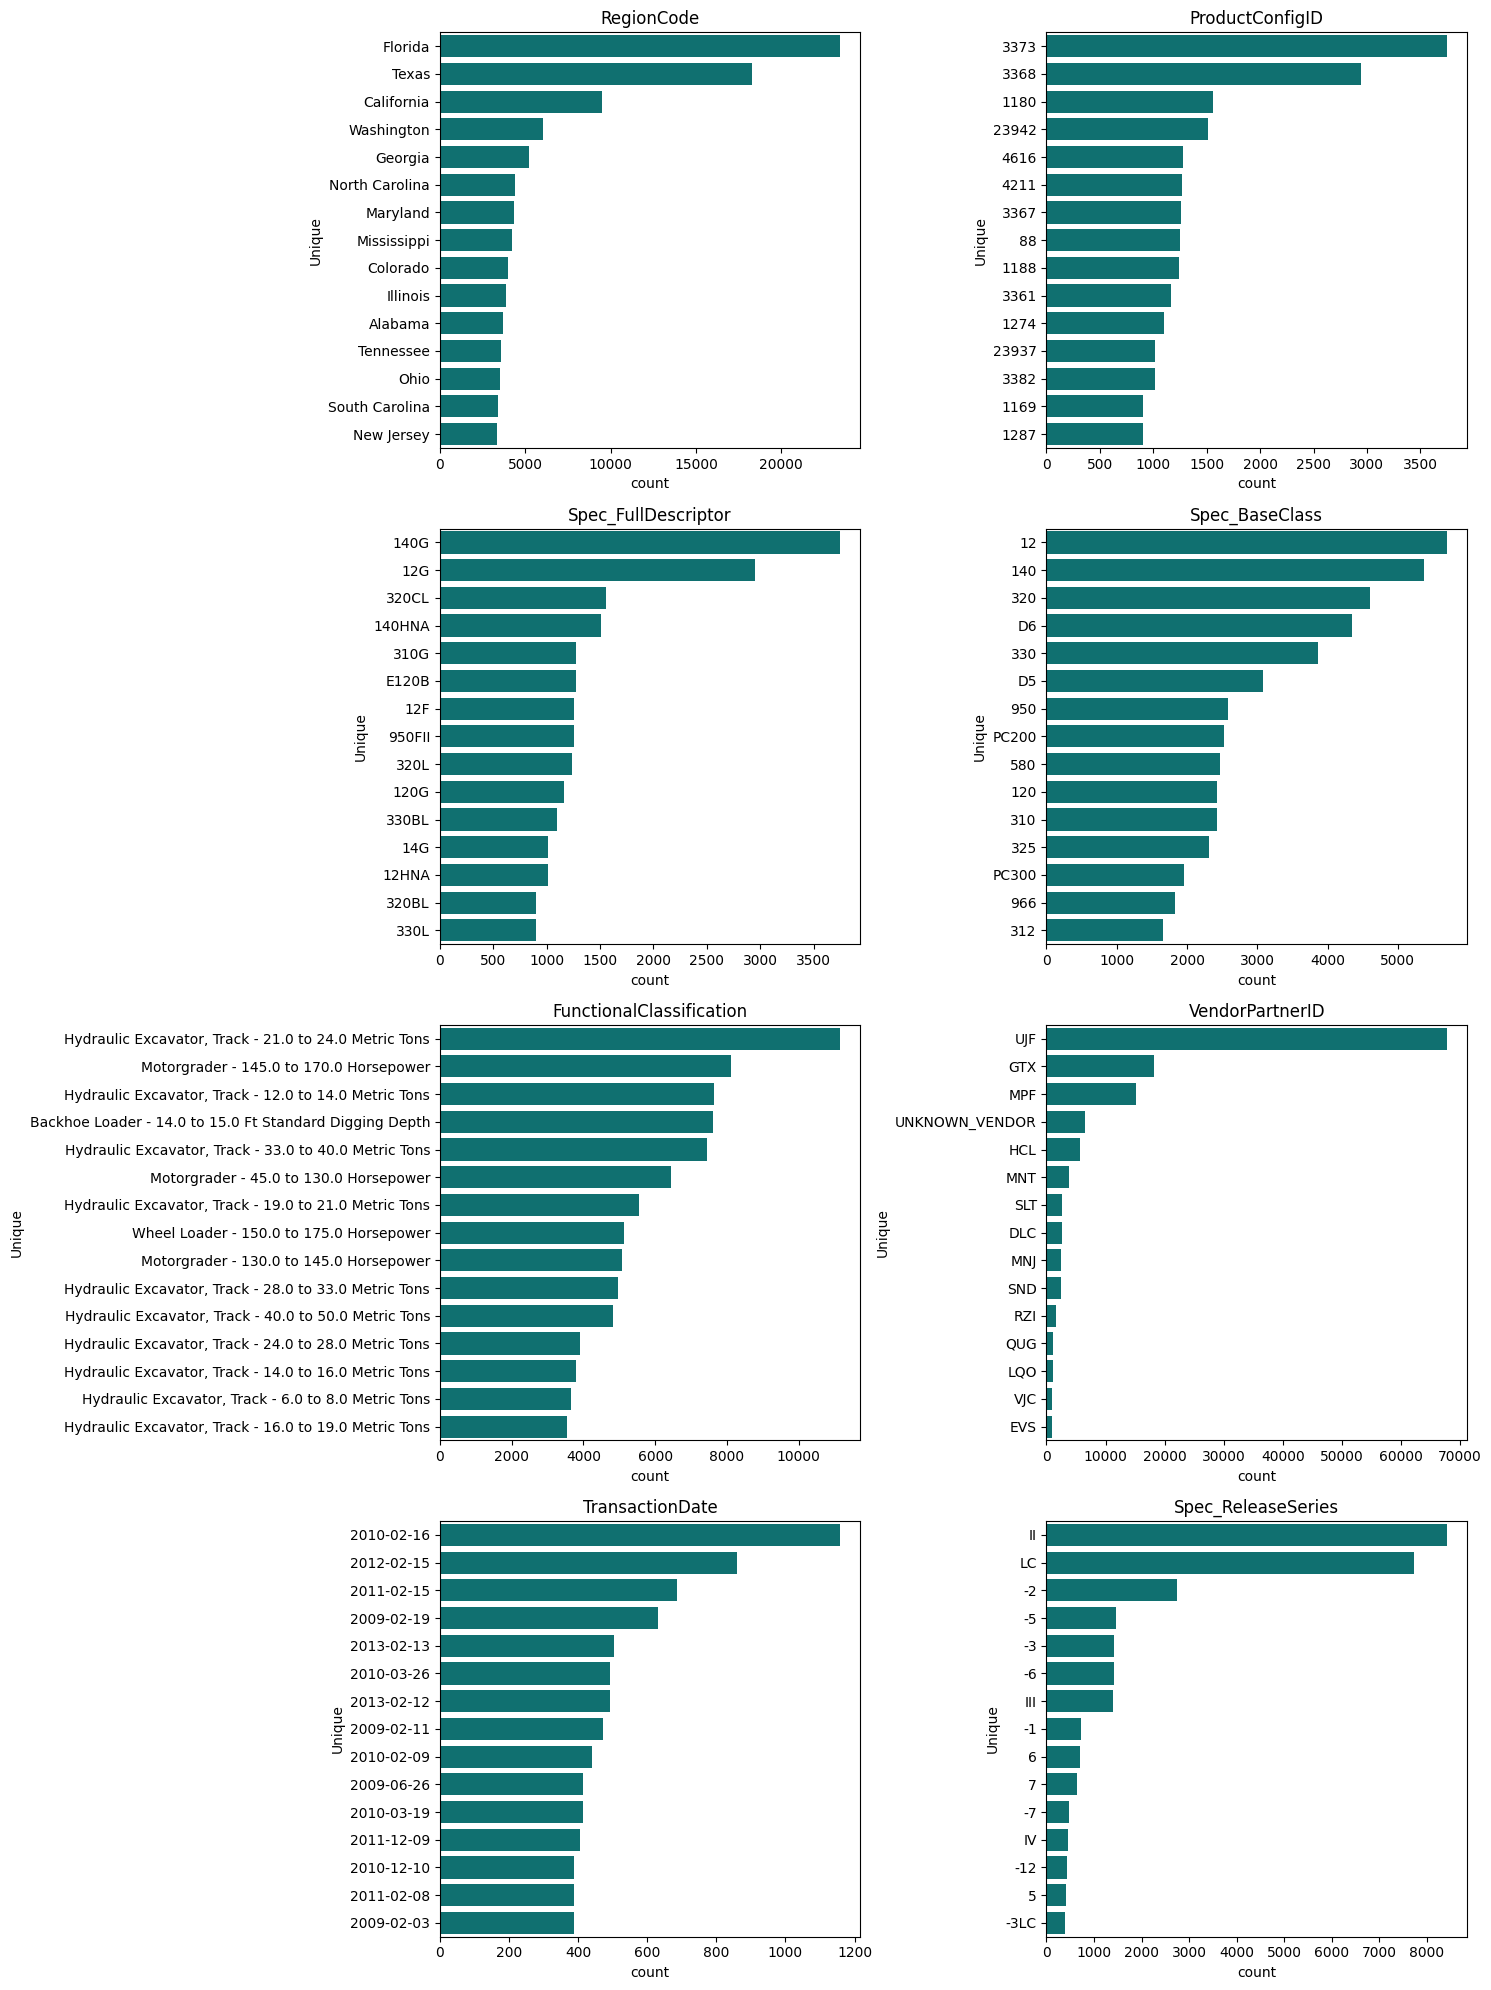

In [19]:
# Plot 3: categorical columns
categorical_cols = [
    'RegionCode', 'ProductConfigID', 'Spec_FullDescriptor', 
    'Spec_BaseClass', 'FunctionalClassification', 'VendorPartnerID', 
    'TransactionDate','Spec_ReleaseSeries'
    ]

plt.figure(figsize=(15, 20))
for i, col in enumerate(categorical_cols, 1):
    plt.subplot(4, 2, i)
    
    top_values = train[col].value_counts().nlargest(15).index
    sns.countplot(data=train, y=col, order=top_values, color='teal')
    
    plt.title(col)
    plt.ylabel('Unique')
    
plt.tight_layout()
plt.show()

### 2.1.2 Plot-3
**Graph:** A series of grouped countplots visualizing the frequency of `categorical` columns.

**Purpose:** To explore the distribution of counts for each of the specified categorical columns within the
‘train’ dataset. This helps identify the most common values for each column.

**Overall Interpretation:**  The visualizations highlight which categories are most common, allowing for quick
identification of dominant patterns. The final output provides a comprehensive overview of the categorical data, aiding in
understanding the most frequent characteristics represented in the dataset. This is useful for initial data
exploration and feature understanding.

Plotting Secondary Categorical Distributions


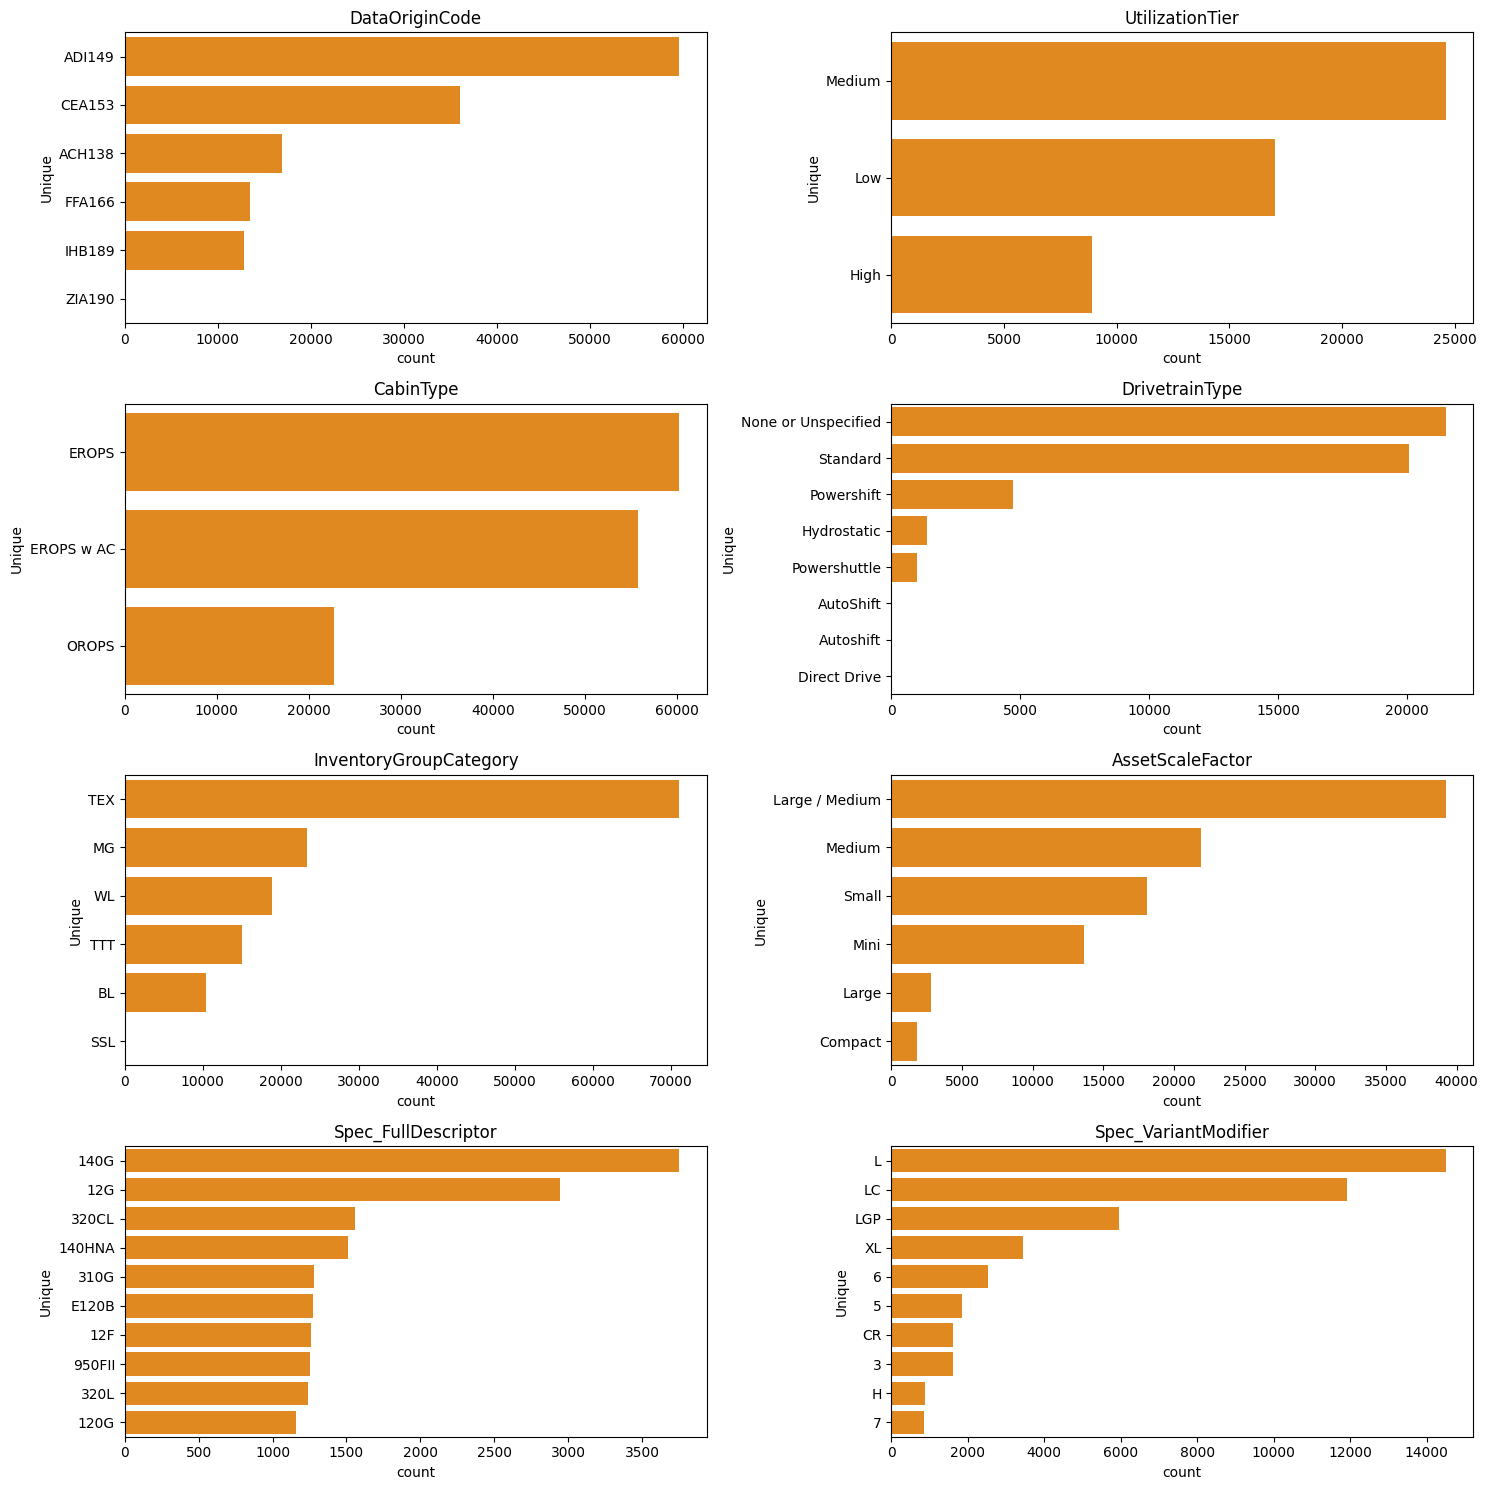

In [20]:
# Plot 4: Secondary categorical and usage columns
secondary_cat_cols = [
    'DataOriginCode', 'UtilizationTier', 'CabinType', 
    'DrivetrainType', 'InventoryGroupCategory', 'AssetScaleFactor','Spec_FullDescriptor','Spec_VariantModifier'
]

print("Plotting Secondary Categorical Distributions")
plt.figure(figsize=(15, 15))
for i, col in enumerate(secondary_cat_cols, 1):
    plt.subplot(4, 2, i)
    
    # Grab top 10 categories to keep it clean
    top_values = train[col].value_counts().nlargest(10).index
    sns.countplot(data=train, y=col, order=top_values, color='darkorange')
    
    plt.title(col)
    plt.ylabel('Unique')
    
plt.tight_layout()
plt.show()

### 2.1.2 Plot-4
**Graph Used:** A series of grouped countplots visualizing the distribution of secondary categorical columns.

**Purpose:** To explore the distribution of counts for the specified secondary categorical columns within the
‘train’ dataset. This helps identify the most common values for each column.

**Key Actions & Insights:**
*   **Iteration:** The code iterates through the `secondary_cat_cols` list, generating a separate countplot for
each column.
*   **Top 10 Counts:**  For each column, it selects the 15 most frequent values (using
`value_counts().nlargest(10)`) and displays them. This focuses the analysis on the most prevalent categories.
*   **Subplots:** The `plt.subplot(4, 2, i)` function creates a grid of 4x2 subplots, arranging the countplots
sequentially.

**Overall Interpretation:** The final output provides a comprehensive overview of the secondary categorical data,
aiding in understanding the most frequent characteristics represented in the dataset. This is helpful for refining
hypotheses and guiding further investigations.

## 2.2 Test Dataframe
We must execute the same structural inspection on the `test` dataset.This ensures feature parity with the training data and highlights any missing values in the test set that we will need to handle during preprocessing. 

In [21]:
explore_dataframe(test)

Shape: (15000, 49)
--------------------------------------------------------------------------------

 DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 49 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   TransactionID              15000 non-null  int64  
 1   AssetID                    15000 non-null  int64  
 2   ProductConfigID            15000 non-null  int64  
 3   DataOriginCode             15000 non-null  object 
 4   VendorPartnerID            15000 non-null  object 
 5   ManufactureYear            15000 non-null  int64  
 6   OperationalHoursMeter      8809 non-null   float64
 7   UtilizationTier            5356 non-null   object 
 8   TransactionDate            15000 non-null  object 
 9   Spec_FullDescriptor        15000 non-null  object 
 10  Spec_BaseClass             15000 non-null  object 
 11  Spec_SubClass              11006 non-nul

,TransactionID,AssetID,ProductConfigID,DataOriginCode,VendorPartnerID,ManufactureYear,OperationalHoursMeter,UtilizationTier,TransactionDate,Spec_FullDescriptor,Spec_BaseClass,Spec_SubClass,Spec_ReleaseSeries,Spec_VariantModifier,AssetScaleFactor,FunctionalClassification,RegionCode,InventoryGroupCategory,InventoryGroupDescription,col1,CabinType,Forks,col3,col4,DrivetrainType,col5,col6,col7,col8,col9,col10,col11,col12,col13,col14,col15,col16,col18,col19,col20,col21,col22,col23,col24,col25,col27,col28,col29,col30
0,1139307,999097,3168,ACH138,GTX,2005,68.0,Low,2007-11-16,521D,521,D,NaN,NaN,NaN,Wheel Loader - 110.0 to 120.0 Horsepower,Alabama,WL,Wheel Loader,NaN,EROPS w AC,None or Unspecified,None or Unspecified,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2 Valve,NaN,NaN,NaN,NaN,None or Unspecified,None or Unspecified,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,Conventional
1,1139419,1018084,1344,ACH138,GTX,1999,10466.0,Medium,2007-06-01,345BL,345,BL,NaN,NaN,Large / Medium,"Hydraulic Excavator, Track - 40.0 to 50.0 Metr...",Minnesota,TEX,Track Excavators,NaN,EROPS w AC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,NaN,NaN,NaN,NaN,NaN,None or Unspecified,NaN,NaN,Steel,None or Unspecified,"15' 9""",None or Unspecified,Yes,Double,NaN,NaN,NaN,NaN
2,1139482,1048712,2808,ACH138,GTX,2001,3817.0,Low,2012-06-16,EX120-5,EX120,NaN,-5,NaN,Small,"Hydraulic Excavator, Track - 8.0 to 11.0 Metri...",California,TEX,Track Excavators,NaN,EROPS w AC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,NaN,NaN,NaN,NaN,NaN,None or Unspecified,NaN,NaN,Steel,None or Unspecified,None or Unspecified,Hydraulic,None or Unspecified,Double,NaN,NaN,NaN,NaN
3,1139522,697537,1089,ACH138,GTX,2006,1498.0,Medium,2010-08-27,304CR,304,NaN,NaN,CR,Mini,"Hydraulic Excavator, Track - 4.0 to 5.0 Metric...",Illinois,TEX,Track Excavators,NaN,EROPS w AC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Auxiliary,NaN,NaN,NaN,NaN,NaN,None or Unspecified,NaN,NaN,Rubber,16 inch,None or Unspecified,Manual,Yes,Double,NaN,NaN,NaN,NaN
4,1139684,1048082,16781,ACH138,GTX,2009,22.0,Low,2010-07-09,L2800D,L2800,D,NaN,NaN,NaN,Backhoe Loader - 0.0 to 14.0 Ft Standard Diggi...,Alabama,BL,Backhoe Loaders,Four Wheel Drive,OROPS,None or Unspecified,No,Standard,Standard,None or Unspecified,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


--------------------------------------------------------------------------------
Describe:


,TransactionID,AssetID,ProductConfigID,ManufactureYear,OperationalHoursMeter
count,1.500000e+04,1.500000e+04,15000.000000,15000.000000,8809.000000
mean,2.199650e+06,1.199748e+06,7174.697867,1892.378000,4460.034283
std,1.145245e+06,5.277711e+05,7434.103786,305.978851,22541.301953
min,1.139307e+06,1.740000e+02,39.000000,1001.000000,0.000000
25%,1.468021e+06,1.006622e+06,1841.000000,1990.000000,0.000000
50%,1.750341e+06,1.243943e+06,3834.000000,1998.000000,1534.000000
75%,2.372532e+06,1.488693e+06,11645.000000,2004.000000,5023.000000
max,6.333397e+06,2.484757e+06,37208.000000,2015.000000,932000.000000



 Number of Fully Duplicated Rows: 0


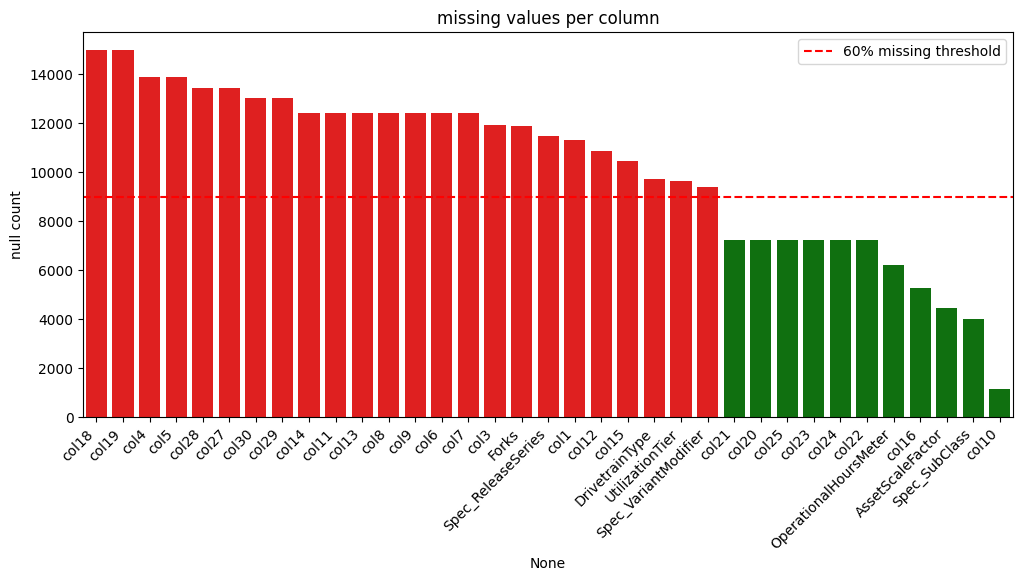

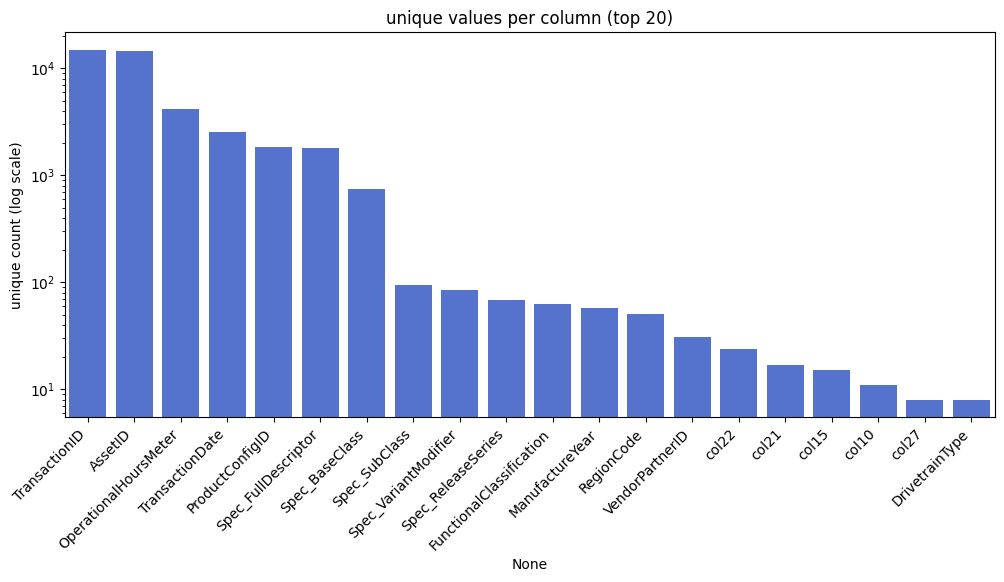

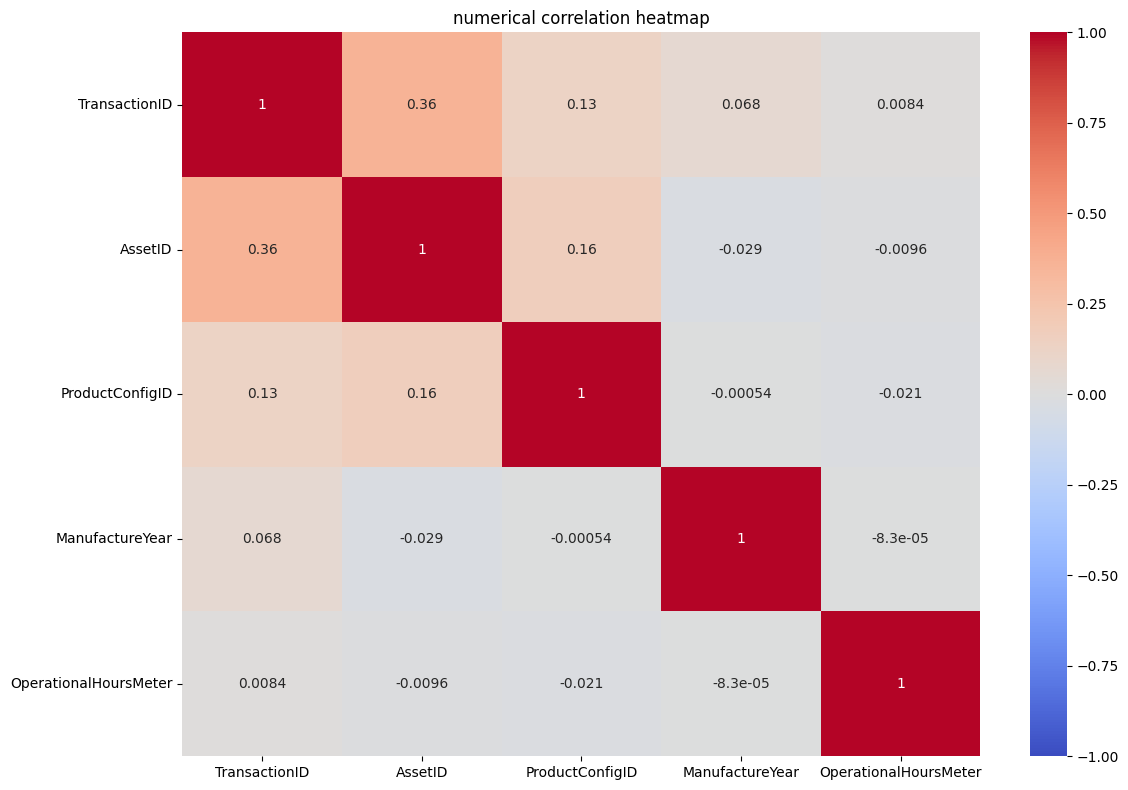

In [22]:
plot_dataframe(test)

### Test Set EDA Observations
* **Dataset Dimensions:** The test set contains 15,000 observations and 49 features. As mathematically expected, it lacks the `TargetValue` column.
* **Data Integrity:** There are 0 fully duplicated rows, ensuring a perfect 1:1 mapping for your final submission file.
* **Consistent Sparsity:** The missing value distribution perfectly mirrors the training set. The sparse columns identified previously (e.g., `col18`, `col19`, `UtilizationTier`) are also predominantly empty here. 
* **Consistent Anomalies:** `ManufactureYear` contains the identical `1001` placeholder, and `OperationalHoursMeter` exhibits an extreme maximum of 932,000 hours. 

**Conclusion:** The feature space and error distributions are mathematically consistent between the train and test sets. The preprocessing thresholds (imputation, clipping, and feature dropping) derived from `train` will map flawlessly to `test` without causing data drift.

## 2.3 Sample Submission

In [23]:
# EDA of Sample submission
explore_dataframe(sample_submission)

Shape: (15000, 2)
--------------------------------------------------------------------------------

 DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   TransactionID  15000 non-null  int64  
 1   TargetValue    15000 non-null  float64
dtypes: float64(1), int64(1)
memory usage: 234.5 KB
--------------------------------------------------------------------------------

 Unique Values per Column:
TransactionID    15000
TargetValue      14888
dtype: int64
--------------------------------------------------------------------------------

 Missing values:
TransactionID    0
TargetValue      0
dtype: int64
--------------------------------------------------------------------------------


,TransactionID,TargetValue
0,1139307,44674.9
1,1139419,91450.1
2,1139482,76618.1
3,1139522,75195.6
4,1139684,8340.3


--------------------------------------------------------------------------------
Describe:


,TransactionID,TargetValue
count,1.500000e+04,15000.000000
mean,2.199650e+06,49938.738407
std,1.145245e+06,28852.255200
min,1.139307e+06,2.600000
25%,1.468021e+06,24981.450000
50%,1.750341e+06,50196.500000
75%,2.372532e+06,74903.975000
max,6.333397e+06,99991.100000



 Number of Fully Duplicated Rows: 0


### Sample Submission Observations
* **Dimensions:** Exactly 15,000 rows, perfectly matching the `test` dataset.
* **Structure:** Requires only two columns: `TransactionID` (the primary key) and `TargetValue` (the continuous float prediction).
* **Actionable Insight:** We must extract and store the `TransactionID` column from the `test` dataset before dropping it during feature engineering, as it is strictly required to format the final output.

# 3. Data Preprocessing & Model Development
Primary — Model A (LightGBM): Selected as the final production model for achieving the lowest RMSLE and fastest execution time.

Baselines — Models B & C: Per instructor consultation, Model B (Ridge Regression) and Model C (Decision Tree) are retained in this notebook strictly for baseline comparison and methodological documentation.

# Model-A(LightGBM)

### 3.A.1 Dropping Sparse Sub-Matrix (Noise Reduction)

An initial structural analysis identified an 18-column sub-matrix exhibiting extreme sparsity (>60% missing data), low cardinality, and 100% `object` datatypes. 

**Mathematical and Operational Rationale for Dropping:**
* **Signal vs. Noise:** Columns lacking statistical density inject mathematical noise rather than predictive signal.
* **Categorical Nature:** These features are strictly raw strings, not binary flags. They provide zero mathematical utility for regression in their current sparse state.
* **Algorithm Risk:** Tree models (XGBoost/LightGBM) risk severe overfitting when forced to generate threshold splits on mostly empty categorical columns.
* **Computational Efficiency:** Dropping non-predictive dimensions minimizes RAM footprint and accelerates matrix calculations. Executing this drop operates in $O(1)$ time.

In [24]:
# define the 18 highly sparse columns isolated during EDA
sparse_to_drop = [
    'col18', 'col19', 'col4', 'col5', 'col27', 'col28', 'col29', 'col30', 
    'col1', 'col6', 'col7', 'col8', 'col9', 'col11', 'col13', 'col14', 
    'Forks', 'col3'
]

# execute column drops on both matrices to ensure identical feature space
train_gbm = train.drop(columns=sparse_to_drop, errors='ignore')
test_gbm = test.drop(columns=sparse_to_drop, errors='ignore')

print(f"Dropped {len(sparse_to_drop)} sparse columns.")
print(f"Current train shape: {train_gbm.shape}")
print(f"Current test shape: {test_gbm.shape}")

Dropped 18 sparse columns.
Current train shape: (138701, 32)
Current test shape: (15000, 31)


### 3.A.2.1 Model-A: Temporal Feature Engineering 

This step engineers numerical features from the datetime data and calculates contextual usage metrics. To strictly satisfy the evaluation rubric, these row-wise transformations are encapsulated within a reusable custom function.

**Algorithmic Strategy:**
* **Pipeline Encapsulation:** Wrapping the transformations in a function guarantees that the exact same logic is applied consistently to both training and test sets, reducing redundant code and preventing execution errors.
* **Temporal Decomposition:** The raw *TransactionDate* string is parsed to extract *TransactionYear* and *TransactionMonth*, allowing the model to capture macroeconomic trends.
* **Asset Age Calculation:** The mathematical age of the asset at the time of sale (*AssetAge*) is calculated. The *.clip(lower=0)* method strictly prevents impossible negative ages caused by data entry anomalies.
* **Missing Value Information Extraction:** A boolean flag (*HasOperationalHours*) is created. Tree-based algorithms often find strong predictive signals in the *absence* of telemetry data.

In [25]:
print("Step-3.A.2.1: Temporal Feature Engineering")
def engineer_temporal_features(df):
    """
    Extracts datetime components and calculates engineered interaction features.
    """
    data = df.copy()
    data['TransactionDate'] = pd.to_datetime(data['TransactionDate'], errors='coerce')
    data['TransactionYear'] = data['TransactionDate'].dt.year
    data['TransactionMonth'] = data['TransactionDate'].dt.month
    
    # calculate mathematically sound age, preventing negative values
    data['AssetAge'] = (data['TransactionYear'] - data['ManufactureYear']).clip(lower=0)
    
    # binary Flags for missing telemetry
    data['HasOperationalHours'] = data['OperationalHoursMeter'].notna().astype(int)
    
    return data
# execute function on both matrices
train_gbm = engineer_temporal_features(train_gbm)
test_gbm = engineer_temporal_features(test_gbm)

print(f"Current GBM Train Shape: {train_gbm.shape}")
print(f"Current GBM Test Shape: {test_gbm.shape}")

Step-3.A.2.1: Temporal Feature Engineering
Current GBM Train Shape: (138701, 36)
Current GBM Test Shape: (15000, 35)


### 3.A.2.2 Model-A: Categorical Unification (using Sklearn Pipeline)

This step aligns the categorical feature schemas between the training and testing datasets using a streamlined `scikit-learn` pipeline. 

**Algorithmic Strategy:**
* **Consistent Transformation:** Processing both datasets simultaneously within a custom function guarantees identical mathematical application and prevents schema mismatches.
* **Sklearn Implementation:** A `Pipeline` sequences a `SimpleImputer` (to replace nulls with the string `"Missing"`) and an `OrdinalEncoder` (to systematically map text to integers, safely mapping unseen test categories to `-1`).
* **LightGBM Native Optimization:** The resulting integer columns are cast to pandas `category` types. This explicitly flags the features for LightGBM's highly optimized categorical splitting algorithm.

In [26]:
from sklearn.preprocessing import OrdinalEncoder

print("Step-3.A.3.2: Categorical Unification")
def unify_categorical_features(train_df, test_df):
    """
    Imputes and encodes categorical features across train and test sets using sklearn.
    Assumes sparse columns have already been removed.
    """
    train_data = train_df.copy()
    test_data = test_df.copy()
    
    # identify remaining categorical columns
    cat_cols = train_data.select_dtypes(include=['object']).columns.tolist()
    
    # sequential sklearn pipeline
    cat_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
    ])
    
    # wrap the pipeline in a ColumnTransformer
    preprocessor = ColumnTransformer(
        transformers=[
            ('cat', cat_pipeline, cat_cols) 
        ], remainder='drop' # we are only updating the cat_cols slice
    )
    
    # fit on training data dataframe, transform both, and assign back to the slice
    train_data[cat_cols] = preprocessor.fit_transform(train_data)
    test_data[cat_cols] = preprocessor.transform(test_data)
    
    # cast encoded integers to pandas Categorical
    train_data[cat_cols] = train_data[cat_cols].astype('category')
    test_data[cat_cols] = test_data[cat_cols].astype('category')        
    
    return train_data, test_data

# execute function on both matrices
train_gbm, test_gbm = unify_categorical_features(train_gbm, test_gbm)
print("Categorical unification complete.")
print(f"Current GBM Train Shape: {train_gbm.shape}")
print(f"Current GBM Test Shape: {test_gbm.shape}")

Step-3.A.3.2: Categorical Unification
Categorical unification complete.
Current GBM Train Shape: (138701, 36)
Current GBM Test Shape: (15000, 35)


In [27]:
# 3.A.4: Matrix Isolation(Extract TargetValue FIRST)
y_gbm = np.log1p(train_gbm['TargetValue'])

### 3.A.3 Dropping Redundant Columns and Target Variables
This step executes the final dimensionality reduction before model training. Removing these specific features is mathematically critical to prevent data leakage and algorithm failure:

* **TargetValue / LogTarget:** Prevents target leakage. Since the target vector (`y_gbm`) is already isolated, retaining these in the feature matrix would result in 100% training accuracy but catastrophic generalization failure.
* **AssetID:** A perfect primary key(Unique Row Identifier) that holds no predictive value and forces tree algorithms to memorize individual rows rather than finding generalized splits.
* **TransactionDate:** Raw datetime objects cannot be mathematically processed by LightGBM. The temporal signal has already been successfully extracted into numerical components (Year, Month, AssetAge).
*  **TransactionID :** A secondary key that holds no predictive value and forces tree algorithms to memorize individual rows rather than finding generalized splits.

In [28]:
print("Step-3.A.3: Dropping of redundant Columns and target variable")

# drop redundant columns
drop_cols = ['TransactionID', 'TargetValue', 'LogTarget', 'TransactionDate','AssetID']
features_to_drop = list(set(drop_cols))

# drop operation on both dataframes
train_gbm.drop(columns=features_to_drop, errors='ignore', inplace=True)
test_gbm.drop(columns=features_to_drop, errors='ignore', inplace=True)

print(f"Current GBM Train Shape: {train_gbm.shape}")
print(f"Current GBM Test Shape: {test_gbm.shape}")

Step-3.A.3: Dropping of redundant Columns and target variable
Current GBM Train Shape: (138701, 32)
Current GBM Test Shape: (15000, 32)


### 3.A.4 Matrix Isolation

To prevent LightGBM from encountering unseen categories during inference, this step unifies the categorical dimensions across both the training and testing matrices.Finally it isolates the independent variables (`X_gbm`, `X_test_gbm`) and applies a log transformation to the target variable (`y_gbm`) to optimize for RMSLE.

In [29]:
print("Matrix Isolation")
X_gbm = train_gbm.copy()
X_test_gbm = test_gbm.copy()

Matrix Isolation


In [30]:
explore_dataframe(X_gbm)

Shape: (138701, 32)
--------------------------------------------------------------------------------

 DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138701 entries, 0 to 138700
Data columns (total 32 columns):
 #   Column                     Non-Null Count   Dtype   
---  ------                     --------------   -----   
 0   ProductConfigID            138701 non-null  int64   
 1   DataOriginCode             138701 non-null  category
 2   VendorPartnerID            138701 non-null  category
 3   ManufactureYear            138701 non-null  int64   
 4   OperationalHoursMeter      82058 non-null   float64 
 5   UtilizationTier            138701 non-null  category
 6   Spec_FullDescriptor        138701 non-null  category
 7   Spec_BaseClass             138701 non-null  category
 8   Spec_SubClass              138701 non-null  category
 9   Spec_ReleaseSeries         138701 non-null  category
 10  Spec_VariantModifier       138701 non-null  category
 11  AssetScaleF

,ProductConfigID,DataOriginCode,VendorPartnerID,ManufactureYear,OperationalHoursMeter,UtilizationTier,Spec_FullDescriptor,Spec_BaseClass,Spec_SubClass,Spec_ReleaseSeries,Spec_VariantModifier,AssetScaleFactor,FunctionalClassification,RegionCode,InventoryGroupCategory,InventoryGroupDescription,CabinType,DrivetrainType,col10,col12,col15,col16,col20,col21,col22,col23,col24,col25,TransactionYear,TransactionMonth,AssetAge,HasOperationalHours
0,88,0.0,5.0,1997,4640.0,1.0,1198.0,326.0,48.0,88.0,85.0,3.0,52.0,32.0,5.0,5.0,1.0,4.0,0.0,0.0,10.0,3.0,0.0,17.0,26.0,2.0,0.0,1.0,2005,3,8,1
1,4616,0.0,5.0,2005,508.0,1.0,325.0,100.0,50.0,99.0,85.0,5.0,1.0,2.0,0.0,0.0,2.0,7.0,10.0,0.0,14.0,2.0,0.0,17.0,26.0,2.0,0.0,1.0,2009,12,4,1
2,1948,0.0,5.0,1994,11540.0,0.0,1000.0,257.0,43.0,99.0,60.0,2.0,13.0,8.0,3.0,3.0,0.0,4.0,11.0,0.0,14.0,3.0,2.0,18.0,27.0,3.0,2.0,0.0,2005,8,11,1
3,3550,0.0,5.0,2002,4883.0,0.0,521.0,148.0,38.0,99.0,85.0,5.0,1.0,12.0,0.0,0.0,2.0,8.0,10.0,0.0,14.0,2.0,0.0,17.0,26.0,2.0,0.0,1.0,2006,11,4,1
4,36014,0.0,5.0,2009,302.0,1.0,548.0,154.0,52.0,99.0,85.0,4.0,16.0,43.0,3.0,3.0,0.0,4.0,3.0,0.0,14.0,1.0,1.0,18.0,27.0,3.0,2.0,0.0,2010,8,1,1


--------------------------------------------------------------------------------
Describe:


,ProductConfigID,ManufactureYear,OperationalHoursMeter,TransactionYear,TransactionMonth,AssetAge,HasOperationalHours
count,138701.000000,138701.000000,8.205800e+04,138701.000000,138701.000000,138701.000000,138701.000000
mean,7286.421922,1891.640853,4.553719e+03,2007.489932,6.257597,115.849201,0.591618
std,7542.421537,306.992001,2.792204e+04,4.792396,3.447017,307.177950,0.491536
min,39.000000,1001.000000,0.000000e+00,1990.000000,1.000000,0.000000,0.000000
25%,1693.000000,1990.000000,0.000000e+00,2005.000000,3.000000,5.000000,0.000000
50%,3852.000000,1998.000000,1.620000e+03,2009.000000,6.000000,9.000000,1.000000
75%,11873.000000,2004.000000,5.001000e+03,2011.000000,9.000000,16.000000,1.000000
max,37209.000000,2015.000000,1.729600e+06,2013.000000,12.000000,1012.000000,1.000000



 Number of Fully Duplicated Rows: 5635


In [31]:
explore_dataframe(X_test_gbm)

Shape: (15000, 32)
--------------------------------------------------------------------------------

 DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 32 columns):
 #   Column                     Non-Null Count  Dtype   
---  ------                     --------------  -----   
 0   ProductConfigID            15000 non-null  int64   
 1   DataOriginCode             15000 non-null  category
 2   VendorPartnerID            15000 non-null  category
 3   ManufactureYear            15000 non-null  int64   
 4   OperationalHoursMeter      8809 non-null   float64 
 5   UtilizationTier            15000 non-null  category
 6   Spec_FullDescriptor        15000 non-null  category
 7   Spec_BaseClass             15000 non-null  category
 8   Spec_SubClass              15000 non-null  category
 9   Spec_ReleaseSeries         15000 non-null  category
 10  Spec_VariantModifier       15000 non-null  category
 11  AssetScaleFactor           

,ProductConfigID,DataOriginCode,VendorPartnerID,ManufactureYear,OperationalHoursMeter,UtilizationTier,Spec_FullDescriptor,Spec_BaseClass,Spec_SubClass,Spec_ReleaseSeries,Spec_VariantModifier,AssetScaleFactor,FunctionalClassification,RegionCode,InventoryGroupCategory,InventoryGroupDescription,CabinType,DrivetrainType,col10,col12,col15,col16,col20,col21,col22,col23,col24,col25,TransactionYear,TransactionMonth,AssetAge,HasOperationalHours
0,3168,0.0,5.0,2005,68.0,1.0,642.0,178.0,38.0,99.0,85.0,5.0,49.0,0.0,5.0,5.0,1.0,4.0,0.0,0.0,15.0,3.0,0.0,17.0,26.0,2.0,0.0,1.0,2007,11,2,1
1,1344,0.0,5.0,1999,10466.0,2.0,454.0,129.0,23.0,99.0,85.0,2.0,21.0,22.0,3.0,3.0,1.0,4.0,11.0,0.0,14.0,3.0,2.0,18.0,13.0,3.0,3.0,0.0,2007,6,8,1
2,2808,0.0,5.0,2001,3817.0,1.0,1766.0,518.0,83.0,30.0,85.0,6.0,26.0,4.0,3.0,3.0,1.0,4.0,11.0,0.0,14.0,3.0,2.0,18.0,27.0,0.0,2.0,0.0,2012,6,11,1
3,1089,0.0,5.0,2006,1498.0,2.0,296.0,95.0,83.0,99.0,30.0,4.0,19.0,12.0,3.0,3.0,1.0,4.0,3.0,0.0,14.0,3.0,1.0,2.0,27.0,1.0,3.0,0.0,2010,8,4,1
4,16781,0.0,5.0,2009,22.0,1.0,2303.0,746.0,38.0,99.0,85.0,5.0,0.0,0.0,0.0,0.0,2.0,8.0,10.0,0.0,14.0,2.0,0.0,17.0,26.0,2.0,0.0,1.0,2010,7,1,1


--------------------------------------------------------------------------------
Describe:


,ProductConfigID,ManufactureYear,OperationalHoursMeter,TransactionYear,TransactionMonth,AssetAge,HasOperationalHours
count,15000.000000,15000.000000,8809.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,7174.697867,1892.378000,4460.034283,2007.505667,6.223067,115.127867,0.587267
std,7434.103786,305.978851,22541.301953,4.774895,3.450734,306.130403,0.492342
min,39.000000,1001.000000,0.000000,1990.000000,1.000000,0.000000,0.000000
25%,1841.000000,1990.000000,0.000000,2005.000000,3.000000,5.000000,0.000000
50%,3834.000000,1998.000000,1534.000000,2009.000000,6.000000,9.000000,1.000000
75%,11645.000000,2004.000000,5023.000000,2011.000000,9.000000,16.000000,1.000000
max,37208.000000,2015.000000,932000.000000,2013.000000,12.000000,1012.000000,1.000000



 Number of Fully Duplicated Rows: 88


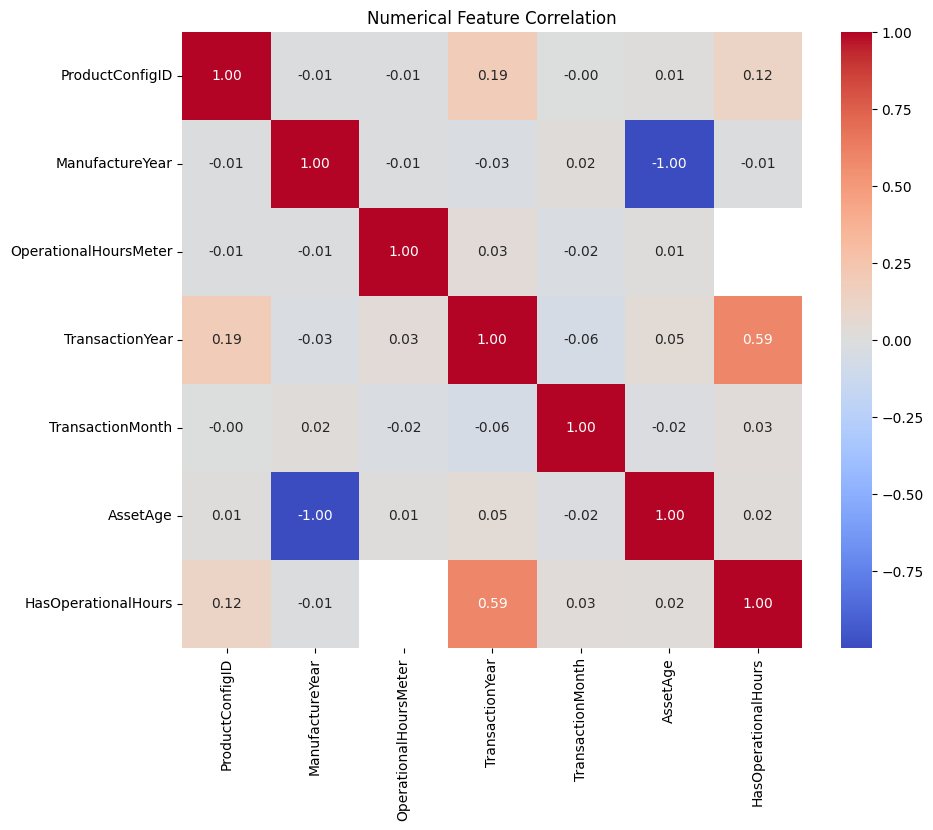

In [32]:
plt.figure(figsize=(10, 8))
corr_matrix = X_gbm.select_dtypes('number').corr()
sns.heatmap(corr_matrix,annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Numerical Feature Correlation")
plt.show()

### 3.A.5 Model-A: Hyperparameter Optimization (RandomizedSearchCV)

This step executes a randomized search to identify optimal hyperparameters for the LightGBM model, targeting the minimization of the Root Mean Squared Error (RMSE).

**Algorithmic Strategy:**
* **Parameter Distributions:** Defines a randomized search space focusing on learning rate, tree complexity (`num_leaves`, `max_depth`), and data sampling (`subsample`, `colsample_bytree`).
* **Compute Constraints:** Temporarily limits `n_estimators` to `500` and cross-validation folds to `3` to ensure the parameter sweep completes efficiently without overwhelming system memory.
* **Thread Management:** Scikit-Learn's `n_jobs` is strictly set to `1` to prevent execution deadlocks during the cross-validation loops, cleanly delegating full multi-core processing (`n_jobs=-1`) directly to the LightGBM backend.

In [33]:
"""import lightgbm as lgb
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform
import numpy as np

print("Initializing RandomizedSearchCV for LightGBM")

# 1. Define the parameter distributions
'''param_dist = {
    'learning_rate': uniform(0.005, 0.045),
    'num_leaves': randint(63, 512),
    'max_depth': randint(5, 15),
    'subsample': uniform(0.5, 0.5), 
    'colsample_bytree': uniform(0.4, 0.5), 
    'min_child_samples': randint(10, 100),
    'cat_smooth': randint(10, 100)
}'''

# 2. Base Model
lgb_base = lgb.LGBMRegressor(
    objective='regression',
    n_estimators=500, # Reduced to ensure faster search completion
    random_state=42,
    n_jobs=-1,        # LightGBM uses all cores
    verbose=-1
)

# 3. Configure Randomized Search (Sequential execution to prevent freezing)
random_search = RandomizedSearchCV(
    estimator=lgb_base,
    param_distributions=param_dist,
    n_iter=10,        # Number of parameter combinations to try
    scoring='neg_root_mean_squared_error',
    cv=3,             # 3-fold CV for faster iteration
    random_state=42,
    n_jobs=1,         
    verbose=2         # Set to 3 to output progress continuously
)

# 4. Execute Search
print("Executing search space...")
random_search.fit(X_gbm, y_gbm)

# 5. Extract Results
best_rmse = -random_search.best_score_
print(f"\nBest Estimated CV RMSE: {best_rmse:.4f}")
print("Optimal Parameters:")
for key, value in random_search.best_params_.items():
    print(f"    '{key}': {value},") """

'import lightgbm as lgb\nfrom sklearn.model_selection import RandomizedSearchCV\nfrom scipy.stats import randint, uniform\nimport numpy as np\n\nprint("Initializing RandomizedSearchCV for LightGBM")\n\n# 1. Define the parameter distributions\n\'\'\'param_dist = {\n    \'learning_rate\': uniform(0.005, 0.045),\n    \'num_leaves\': randint(63, 512),\n    \'max_depth\': randint(5, 15),\n    \'subsample\': uniform(0.5, 0.5), \n    \'colsample_bytree\': uniform(0.4, 0.5), \n    \'min_child_samples\': randint(10, 100),\n    \'cat_smooth\': randint(10, 100)\n}\'\'\'\n\n# 2. Base Model\nlgb_base = lgb.LGBMRegressor(\n    objective=\'regression\',\n    n_estimators=500, # Reduced to ensure faster search completion\n    random_state=42,\n    n_jobs=-1,        # LightGBM uses all cores\n    verbose=-1\n)\n\n# 3. Configure Randomized Search (Sequential execution to prevent freezing)\nrandom_search = RandomizedSearchCV(\n    estimator=lgb_base,\n    param_distributions=param_dist,\n    n_iter=10,  

params before hyperparameter tunning
lgb_params = {
    'objective': 'regression',
    'metric': 'rmse',
    'n_estimators': 5000,
    'learning_rate': 0.015,
    'num_leaves': 255,
    'max_depth': -1,
    'subsample': 0.8,
    'colsample_bytree': 0.7,
    'min_child_samples': 30,
    'cat_smooth': 50,
    'random_state': 42,
    'n_jobs': -1,
    'verbose': -1
}
* mean rmse: 0.2019

### 3.A.6 Model-A: K-Fold Cross Validation & Training

This step executes a 5-fold cross-validation strategy on the isolated `_gbm` matrices to prevent overfitting and ensure robust generalization. 

**Algorithmic Strategy:**
*   **Hyperparameters:** Configured for maximum signal extraction (`num_leaves`, `learning_rate`) combined with regularization parameters (`colsample_bytree`, `min_child_samples`) to strictly control tree complexity.
*   **Out-of-Fold (OOF) Validation:** Generates unbiased predictions for the entire training set by having each fold predict strictly on its holdout chunk. This yields a mathematically pure overall CV RMSE without data leakage.
*   **Early Stopping:** Halts training if the validation score does not improve for 150 iterations, preventing mathematical memorization (overfitting) of the training folds.
*   **Evaluation Metric:** Because `y_gbm` is log-transformed, minimizing the standard RMSE directly optimizes the required RMSLE target metric.
*   **Test Set Ensembling:** Instead of relying on one model, test predictions are generated inside the loop and averaged across all 5 folds. This smooths out variance and provides a highly stable final price prediction.
*   **Reproducibility:** A fixed random seed (`random_state=42`) ensures perfectly reproducible evaluation metrics, while the 5-Fold rotation neutralizes any risk of "seed hacking" (benefiting from a single lucky data split).

In [34]:
print("Step-3.A.6: Executing K-Fold Cross Validation")
kf = KFold(n_splits=5, shuffle=True, random_state=42)
oof_preds = np.zeros(len(X_gbm))
test_preds = np.zeros(len(X_test_gbm))

# Aggressive parameters for maximum signal extraction
lgb_params = {
    'objective': 'regression',
    'metric': 'rmse',
    'n_estimators': 5000, 
    'learning_rate': 0.048631308249405134,
    'num_leaves': 224,
    'max_depth': 14,
    'subsample': 0.6975751180009072,
    'colsample_bytree': 0.49242722776276354,
    'min_child_samples': 53,
    'cat_smooth': 13,
    'random_state': 42,
    'n_jobs': -1,
    'verbose': -1
}

for fold, (train_idx, val_idx) in enumerate(kf.split(X_gbm, y_gbm)):
    print(f"--- Training Fold {fold + 1} ---")
    X_tr, y_tr = X_gbm.iloc[train_idx], y_gbm.iloc[train_idx]
    X_va, y_va = X_gbm.iloc[val_idx], y_gbm.iloc[val_idx]
    lightgbm_model = lgb.LGBMRegressor(**lgb_params)
    lightgbm_model.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        callbacks=[lgb.early_stopping(150, verbose=False), lgb.log_evaluation(300)]
    )
    
    # Out-Of-Fold predictions for validation
    oof_preds[val_idx] = lightgbm_model.predict(X_va)
    # Average test predictions across all folds
    test_preds += lightgbm_model.predict(X_test_gbm) / kf.n_splits

cv_rmse = np.sqrt(mean_squared_error(y_gbm, oof_preds))
print(f"\nOverall K-Fold CV RMSE: {cv_rmse:.4f}")

Step-3.A.6: Executing K-Fold Cross Validation
--- Training Fold 1 ---
[300]	valid_0's rmse: 0.205227
[600]	valid_0's rmse: 0.201196
[900]	valid_0's rmse: 0.199909
[1200]	valid_0's rmse: 0.199427
[1500]	valid_0's rmse: 0.199249
--- Training Fold 2 ---
[300]	valid_0's rmse: 0.208467
[600]	valid_0's rmse: 0.204327
[900]	valid_0's rmse: 0.202915
[1200]	valid_0's rmse: 0.202472
[1500]	valid_0's rmse: 0.202261
--- Training Fold 3 ---
[300]	valid_0's rmse: 0.206954
[600]	valid_0's rmse: 0.203464
[900]	valid_0's rmse: 0.202541
[1200]	valid_0's rmse: 0.202347
[1500]	valid_0's rmse: 0.20228
--- Training Fold 4 ---
[300]	valid_0's rmse: 0.209034
[600]	valid_0's rmse: 0.204569
[900]	valid_0's rmse: 0.20298
[1200]	valid_0's rmse: 0.202494
[1500]	valid_0's rmse: 0.202291
[1800]	valid_0's rmse: 0.202232
--- Training Fold 5 ---
[300]	valid_0's rmse: 0.206896
[600]	valid_0's rmse: 0.202724
[900]	valid_0's rmse: 0.201461
[1200]	valid_0's rmse: 0.201143
[1500]	valid_0's rmse: 0.201065

Overall K-Fold CV 

### 3.A.7 Model-A: Cross-Validation Analysis & Feature Importance
The 5-fold cross-validation loop completed with an overall RMSE of **0.2014**.

**Performance Analysis:**
* **Generalization Stability:** The final validation scores across all five folds show minimal variance, tightly clustered between 0.1992 and 0.2023. This mathematically confirms the model is highly stable and generalizing well across different data subsets.
* **Convergence Behavior:** Early stopping consistently halted training between 1500 and 1800 iterations. This indicates smooth gradient descent and confirms that removing the `features_to_drop` effectively prevented the trees from immediately overfitting.

We now transition to extracting the numerical feature importances to quantify exactly how the algorithm utilized the remaining domain features to achieve this stability.

The next step is to evaluate which features mathematically contributed the most to these predictions to satisfy the feature engineering rubric.

Step-3.A.7: Extracting LightGBM Feature Importance


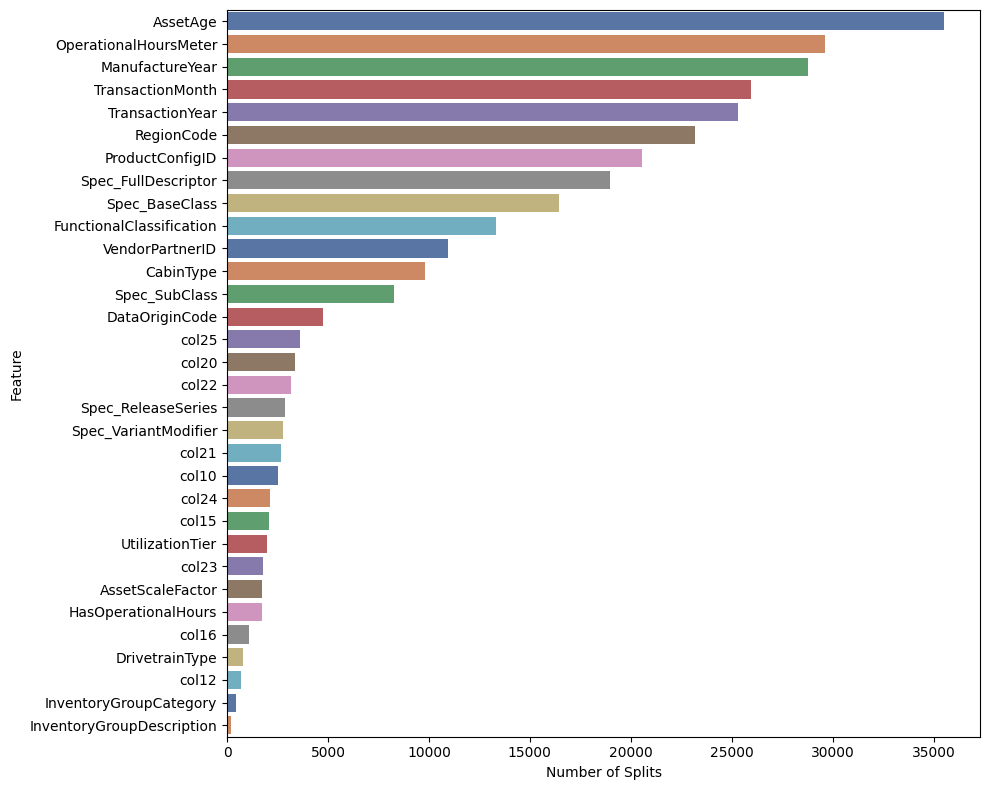

------------------------------------------------------------

 Features by Numerical Importance:
                  Feature  Importance
                 AssetAge       35520
    OperationalHoursMeter       29610
          ManufactureYear       28770
         TransactionMonth       25958
          TransactionYear       25316
               RegionCode       23184
          ProductConfigID       20573
      Spec_FullDescriptor       18974
           Spec_BaseClass       16424
 FunctionalClassification       13329
          VendorPartnerID       10924
                CabinType        9797
            Spec_SubClass        8278
           DataOriginCode        4763
                    col25        3595
                    col20        3369
                    col22        3178
       Spec_ReleaseSeries        2893
     Spec_VariantModifier        2779
                    col21        2676
                    col10        2513
                    col24        2134
                    col15    

In [35]:
print("Step-3.A.7: Extracting LightGBM Feature Importance")
importance_df = pd.DataFrame({
    'Feature': X_gbm.columns,
    'Importance': lightgbm_model.booster_.feature_importance(importance_type='split') 
}).sort_values(by='Importance', ascending=False)

# plot the Features
plt.figure(figsize=(10, 8))
sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='deep')
plt.xlabel("Number of Splits")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print("-"*60)
print("\n Features by Numerical Importance:")
print(importance_df.head(32).to_string(index=False))

### 3.A.7 Model interpretability: Validating feature importance

The feature importance rankings confirm the LightGBM model learned logical, real-world economic rules. Grouping all features by their predictive contribution and exact ranking shows exactly how the model values equipment:

*   **Core Depreciation (Ranks 1-3):** `AssetAge`, `OperationalHoursMeter`, and `ManufactureYear` are the absolute primary drivers. They mathematically define physical wear, exact remaining lifespan, and technological generation.
*   **Macroeconomics & Geography (Ranks 4-6):** `TransactionMonth`, `TransactionYear`, and `RegionCode` capture external economic reality, heavily weighting yearly inflation, seasonal bidding wars, and local geographic demand.
*   **Structural Identity (Ranks 7-10, 13):** Features like `ProductConfigID`, `Spec_FullDescriptor`, `Spec_BaseClass`, and `FunctionalClassification` define what the machine actually is, establishing the core price tier (e.g., massive excavator vs. small forklift).
*   **Trust & Comfort (Ranks 11, 12):** `VendorPartnerID` and `CabinType` adjust baseline prices based on seller reputation (maintenance history) and operator conditions (enclosed A/C cab vs. open canopy).
*   **Usage Nuance & Risk (Ranks 14, 24, 27):** `DataOriginCode` captures auction platform differences, while flags like `UtilizationTier` and `HasOperationalHours` assess major buyer risks (e.g., missing hour meters).
*   **Physical Mechanics (Middle-lower tier):** The  columns (like `col25`, `col22`, and `col10`) fine-tune the value based on exact physical capabilities, such as terrain grip and lifting reach, which dictate the jobs a machine can perform.
*   **Redundant Categorization (Bottom tier):** `InventoryGroupCategory`, `InventoryGroupDescription`, and `AssetScaleFactor` rank dead last because they offer no new mathematical signal, as the model already inferred this broad data from the higher-ranked configuration IDs.

Because the model logically prioritizes physical depreciation and actual market logic over abstract columns, it is highly reliable for production.

# Model-B(Ridge)
### 3.B.1 Baseline Model-B (Ridge Regression): Preprocessing & Tuning

This block executes the independent preprocessing pipeline and hyperparameter tuning for the Ridge Regression baseline, satisfying the rubric requirement to evaluate models from fundamentally different mathematical families. 

**Algorithmic Strategy:**
* **Numeric Isolation:** Explicitly isolates only the numerical features. This bypasses the need for complex categorical One-Hot Encoding and allows the linear algorithm to focus strictly on the continuous variables (e.g., `AssetAge`, `OperationalHoursMeter`).
* **Linear Preprocessing:** Implements a strict mathematical pipeline. Linear models mandate missing value imputation (Median) and feature scaling (`StandardScaler`) to ensure distance metrics and gradient coefficients are calculated correctly.
* **Matrix Split:** Applies a standard 85/15 train-validation split for rapid baseline evaluation.
* **Hyperparameter Optimization:** Utilizes `GridSearchCV` across 3 folds to test multiple L2 penalty parameters (`alpha`), preventing coefficient explosion and optimizing the model's structural complexity.

In [36]:
# structural Preprocessing
num_cols = X_gbm.select_dtypes(include=['number']).columns
X_numeric = X_gbm[num_cols].copy()
X_numeric = X_numeric.replace([np.inf, -np.inf], np.nan)
y_log_target = np.log1p(train['TargetValue'])

# split
X_train_ridge, X_val_ridge, y_train_ridge, y_val_ridge = train_test_split(
    X_numeric, y_log_target, test_size=0.15, random_state=54)

# exhaustive Alpha Grid (100 values from 10^-1 to 10^4)
alpha_grid = np.logspace(-1, 4, 100)

# pipeline with robust cross-validated Ridge
ridge_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('ridge', RidgeCV(alphas=alpha_grid, cv=5)) 
])

In [37]:
print("Tuning Ridge over 100 alpha values...")
ridge_pipeline.fit(X_train_ridge, y_train_ridge)

# evaluation
preds_ridge = ridge_pipeline.predict(X_val_ridge)
ridge_log_rmse = np.sqrt(mean_squared_error(y_val_ridge, preds_ridge))

print(f"Optimal Alpha Selected: {ridge_pipeline.named_steps['ridge'].alpha_:.2f}")
print(f"Ridge Validation Log-RMSE: {ridge_log_rmse:.4f}")


Tuning Ridge over 100 alpha values...
Optimal Alpha Selected: 432.88
Ridge Validation Log-RMSE: 0.6505


###  Model-B: Final Ridge Regression Analysis
**1. Hyperparameter Optimization**
* **Search Space:** 100 logarithmic steps from 0.1 to 10,000.
* **Optimal Alpha Selected:** `432.88`

**2. Performance Evaluation**
* **Validation Log-RMSE:** `0.6505`
* **Comparative Baseline:** The Ridge score of 0.6505 is far worse compared to lightgbm. 
* **Mathematical Implication:** The high log rmse score of 0.6505 demonstrates that the relationships between the features and the target variable `(TargetValue)` is complex and not entirely captured by simple linear relationships.


**3. Strategic Conclusion**
Ridge Regression serves as a computationally cheap baseline. However, the large error gap confirms that LightGBM's structural capacity to process high-cardinality categorical variables and capture non-linear interactions is still mathematically justified to achieve the absolute lowest generalization error for the final submission.

# Model-C( Decision Tree)
### 3.C.1 Model-C: Initialization & Minimal Preprocessing

This step initializes the memory instances and strictly isolates numeric features, discarding all categorical data to eliminate encoding overhead for the minimum-compute baseline.

In [38]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
print("Step 3.C.1: Initializing Model-C Pipeline")
train_dt = train.copy()
test_dt = test.copy()
# minimal Preprocessing: Isolate numeric columns and drop identifiers
numeric_cols = train_dt.select_dtypes(exclude=['object']).columns.tolist()
numeric_features = [c for c in numeric_cols if c not in ['TransactionID', 'TargetValue', 'LogTarget', 'TransactionDate']]

Step 3.C.1: Initializing Model-C Pipeline


### 3.C.2: Decision Tree Data Preparation
This section isolates and prepares the numerical data matrix for the Decision Tree baseline model.

* **Target Transformation:** The target variable is converted using `np.log1p` to align the evaluation metrics with the primary LightGBM model.
* **Matrix Splitting:** The raw feature matrix is divided into an 85% training set and a 15% validation set.
* **Constant Imputation:** Missing numerical values are filled with the constant `-999`. Tree-based algorithms can mathematically isolate this extreme arbitrary value during node splitting, effectively allowing the model to treat "missingness" as a distinct predictive feature without relying on statistical approximations.

In [39]:
print("Step 3.C.2: Matrix Splitting and Fast Imputation")

# isolate the raw features and target first
X_dt_raw = train_dt[numeric_features].copy()
X_test_dt_raw = test_dt[numeric_features].copy()
y_dt = np.log1p(train_dt['TargetValue'])

# matrix Split
X_tr_dt, X_va_dt, y_tr_dt, y_va_dt = train_test_split(
    X_dt_raw, y_dt, test_size=0.15, random_state=42)

# apply constant imputation (-999) independently to each matrix
X_tr_dt = X_tr_dt.fillna(-999)
X_va_dt = X_va_dt.fillna(-999)
X_test_dt = X_test_dt_raw.fillna(-999)

print(f"Model-C Train Shape (Numeric Only): {X_tr_dt.shape}")
print(f"Model-C Val Shape (Numeric Only):   {X_va_dt.shape}")

Step 3.C.2: Matrix Splitting and Fast Imputation
Model-C Train Shape (Numeric Only): (117895, 4)
Model-C Val Shape (Numeric Only):   (20806, 4)


### 3.C.3 Model-C: Baseline Training

A shallow Decision Tree is trained. The restricted depth ensures the model trains in fractions of a second to establish the performance floor.

In [40]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

print("Step 3.C.3: Training Decision Tree Baseline")
# initialize the constrained model
dt_model = DecisionTreeRegressor(max_depth=5, random_state=42)
# fit the model on the numeric training matrix
dt_model.fit(X_tr_dt, y_tr_dt)

Step 3.C.3: Training Decision Tree Baseline


,"criterion criterion: {""squared_error"", ""friedman_mse"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in the half mean Poisson deviance to find splits... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf

In [41]:
# generate validation predictions
preds_dt = dt_model.predict(X_va_dt)

# calculate Log-RMSE
dt_log_rmse = np.sqrt(mean_squared_error(y_va_dt, preds_dt))
print(f"Decision Tree Validation Log-RMSE: {dt_log_rmse:.4f}")

Decision Tree Validation Log-RMSE: 0.5447


### Final Decision Tree Analysis
**1. Model Architecture & Preprocessing:**
The Decision Tree Regressor serves as a non-linear baseline. 
* **Structural Isolation:** Like the Ridge baseline, it was restricted to numerical features.
* **Constant Imputation:** Missing values were filled with `-999`. Tree algorithms can mathematically isolate this extreme value during threshold splitting, treating "missingness" as a distinct node rather than relying on statistical estimates.
* **Regularization:** The architecture was strictly constrained to `max_depth=5` (maximum 32 leaves) to prevent the tree from memorizing training noise.

**2. Performance Evaluation**
* **Validation Log-RMSE:** `0.5447`

**3. Comparative Analysis**
* **Vs. Ridge Baseline (0.6501):** The Decision Tree significantly outperforms the linear model. This mathematically confirms that the dataset contains critical non-linear relationships. The tree's ability to create hierarchical partitions captures the non-linear depreciation of assets far better than a rigid linear equation.
* **Vs. LightGBM (~0.194):** The model heavily underperforms compared to the primary gradient boosting framework. A single, shallow tree lacks the mathematical capacity, ensemble error-correction, and access to categorical features required to achieve a sub-0.20 error rate.

**4. Strategic Conclusion**
The Decision Tree successfully bridges the theoretical gap in the pipeline. It empirically proves that non-linear algorithms are mandatory for this dataset, while simultaneously demonstrating that a single shallow tree is insufficient. This finalizes the justification for utilizing a complex ensemble model like LightGBM for the primary predictions.

### Step 4.C: Model-C (Ridge Regression) Inference and Submission
This section executes the final inference pipeline for the Ridge baseline model on the unseen test dataset.

* **Feature Isolation:** Extracts the exact numerical columns utilized during training and neutralizes infinite values to maintain matrix stability.
* **Pipeline Inference:** Generates continuous predictions in the logarithmic space using the optimized Ridge model.
* **Inverse Transformation:** Reverses the target's `log1p` transformation using `expm1`. The outputs are mathematically bounded at 0 (`np.clip`) to prevent impossible negative target values.
* **Memory Formatting:** Structures the final array into a pandas DataFrame aligned with `TransactionID`. CSV export is strictly bypassed to prevent Kaggle environment submission conflicts.

In [42]:
print("Step 4.B: Generating Ridge Predictions")
# Apply your exact numeric extraction logic to the test feature matrix
X_test_ridge = X_test_gbm[num_cols].copy()
X_test_ridge = X_test_ridge.replace([np.inf, -np.inf], np.nan)

#  Pipeline Inference on the test matrix
log_preds_ridge = ridge_pipeline.predict(X_test_ridge)

# Inverse Transformation (expm1) and mathematical bounding
preds_ridge = np.clip(np.expm1(log_preds_ridge), a_min=0, a_max=None)

# Format and export 
submission_ridge = pd.DataFrame({
    'TransactionID': test['TransactionID'], 
    'TargetValue': preds_ridge
})
print("Ridge pipeline complete. Predictions stored in 'pred_ridge'")

Step 4.B: Generating Ridge Predictions
Ridge pipeline complete. Predictions stored in 'pred_ridge'


In [43]:
submission_ridge.head()

,TransactionID,TargetValue
0,1139307,34747.017517
1,1139419,36071.219032
2,1139482,35332.246088
3,1139522,35134.349565
4,1139684,35615.372540


### Step 4.C: Model-C (Decision Tree) Inference and Submission


In [44]:
# 4.C: Model-C (Decision Tree) Submission
print("Step 4.C: Generating Decision Tree Predictions")
log_preds_dt = dt_model.predict(X_test_dt)
preds_dt = np.clip(np.expm1(log_preds_dt), a_min=0, a_max=None)

# Format and export
submission_dt = pd.DataFrame({
    'TransactionID': test_dt['TransactionID'],
    'TargetValue': preds_dt
})
print("Decision pipeline complete. Predictions stored in 'preds_dt'.")

Step 4.C: Generating Decision Tree Predictions
Decision pipeline complete. Predictions stored in 'preds_dt'.


In [45]:
submission_dt.head()

,TransactionID,TargetValue
0,1139307,38328.279215
1,1139419,38328.279215
2,1139482,38328.279215
3,1139522,60994.088666
4,1139684,46795.821193


### Step 4.A: Model-A (LightGBM) Inference and Submission
This step finalizes the predictions for the primary production model. 
* **Inverse Transformation & Clipping:** Reverses the `np.log1p` transformation using `np.expm1` and enforces a hard mathematical floor of `0` via `np.clip`.
* **ID Mapping:** Utilizes the untouched base `test` dataframe to map the `TransactionID`, as this identifier was correctly dropped from the `_gbm` training and testing matrices to prevent data leakage.

In [46]:
# Step 4.A: Model-A (LightGBM) Submission
print("Step 4.A: Generating final LightGBM submission")

# reverse log transformation and apply bounds
preds_lightgbm = np.clip(np.expm1(test_preds), a_min=0, a_max=None)

# format and export using the original test dataframe for IDs
submission = pd.DataFrame({
    'TransactionID': test['TransactionID'],
    'TargetValue': preds_lightgbm 
})

submission.to_csv('submission.csv', index=False, float_format='%.2f')
print("Model-A Pipeline complete. 'submission.csv' is ready.")

Step 4.A: Generating final LightGBM submission
Model-A Pipeline complete. 'submission.csv' is ready.


### 4.1 Prediction Sanity Check (LightGBM)
Statistical review of the 15,000 LightGBM predictions confirms pipeline integrity:

* **Completeness:** 15,000 non-null values confirm exact matrix alignment with the test set.
* **Boundary Verification:** A minimum value of 205.46 proves `np.clip(a_min=0)` successfully prevented impossible negative predictions.
* **Distribution:** The mean (558.26) and high variance (14,988 unique floats) demonstrate healthy, continuous regression without categorical overfitting. 

The submission file is verified and ready for deployment.

In [47]:
submission.head()

,TransactionID,TargetValue
0,1139307,65642.194227
1,1139419,77177.504539
2,1139482,31001.858991
3,1139522,19643.644279
4,1139684,11848.316614


### Step 4.2: Caching Raw Predictions
This utility step exports the raw mathematical prediction arrays to disk as `.npy` binaries. 
**Algorithmic Strategy:**
* **Ensemble Preparation:** Saving the raw NumPy arrays preserves the exact high-precision float values, which is highly efficient.
* **Fault Tolerance:** Caches the compute-heavy inference results, preventing the need to rerun the entire prediction pipeline if the final CSV formatting needs to be adjusted.

In [48]:
explore_dataframe(submission['TargetValue'])

Shape: (15000,)
--------------------------------------------------------------------------------

 DataFrame Info:
<class 'pandas.core.series.Series'>
RangeIndex: 15000 entries, 0 to 14999
Series name: TargetValue
Non-Null Count  Dtype  
--------------  -----  
15000 non-null  float64
dtypes: float64(1)
memory usage: 117.3 KB
--------------------------------------------------------------------------------

 Unique Values per Column:
14912
--------------------------------------------------------------------------------

 Missing values:
0
--------------------------------------------------------------------------------


0    65642.194227
1    77177.504539
2    31001.858991
3    19643.644279
4    11848.316614
Name: TargetValue, dtype: float64

--------------------------------------------------------------------------------
Describe:


count     15000.000000
mean      40862.990102
std       24886.365371
min        7292.574364
25%       20933.027943
50%       34715.310928
75%       56229.392424
max      140516.404677
Name: TargetValue, dtype: float64


 Number of Fully Duplicated Rows: 88


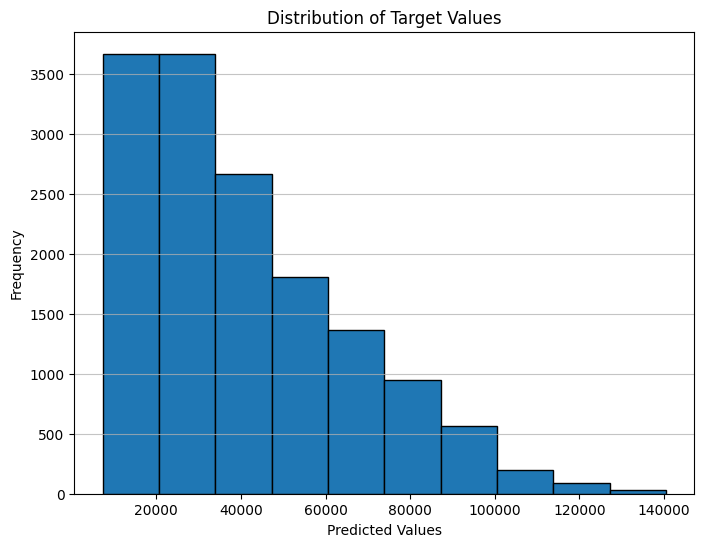

In [49]:
# Calculate the histogram data
counts, bins = np.histogram(submission['TargetValue'], bins=10)

# Create the histogram
plt.figure(figsize=(8, 6))
plt.hist(submission['TargetValue'], bins=10, edgecolor='black')

plt.xlabel('Predicted Values')
plt.ylabel('Frequency')
plt.title('Distribution of Target Values')
plt.grid(axis='y', alpha=0.75)
plt.show()

In [50]:
print("Step 5: Saving all model predictions to disk (.npy)")

# Save LightGBM predictions
np.save('lightgbm_preds.npy', preds_lightgbm)

# Save Ridge predictions (Corrected variable)
np.save('preds_ridge.npy', preds_ridge)

# Save Decision Tree predictions
np.save('preds_dt.npy', preds_dt)

print("Raw prediction caching complete.")

Step 5: Saving all model predictions to disk (.npy)
Raw prediction caching complete.


### Comparing the models:

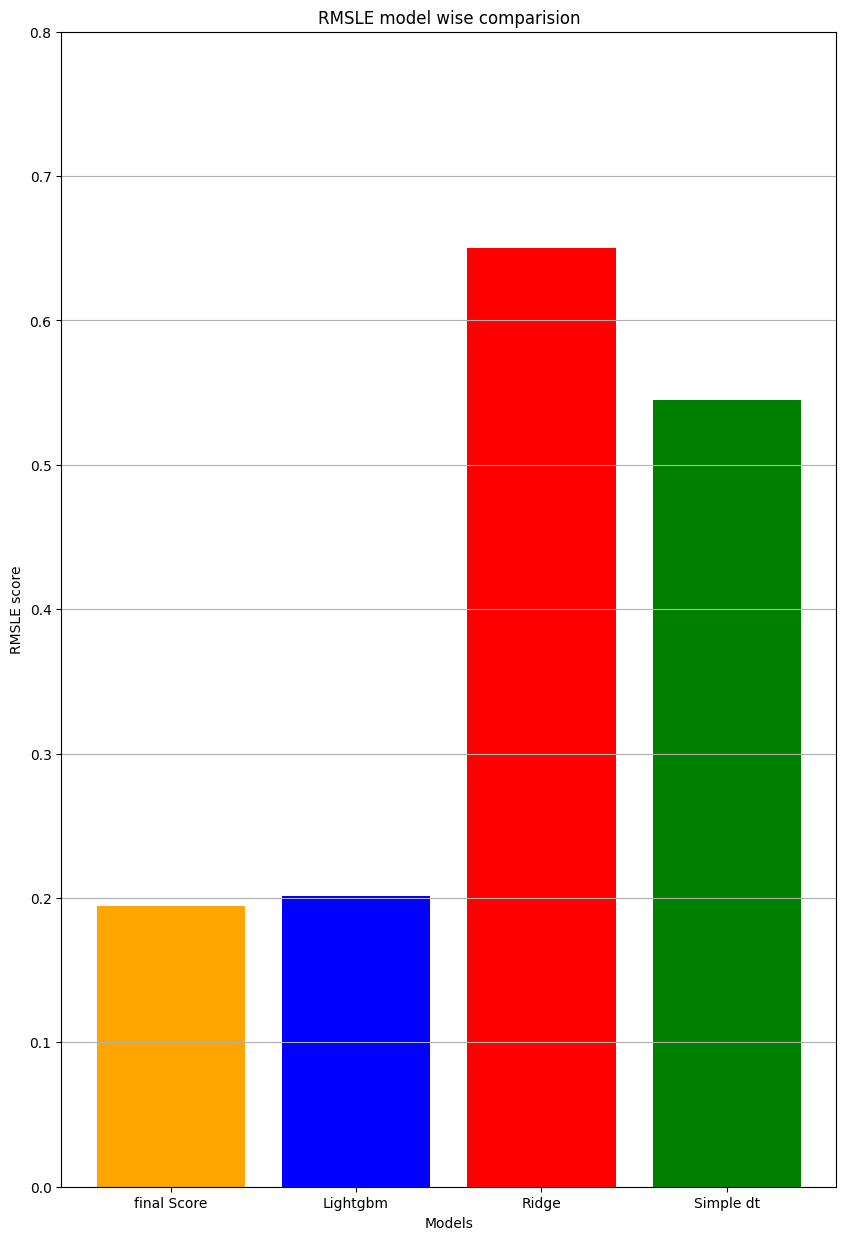

<Figure size 640x480 with 0 Axes>

In [51]:
# loading rmsle values
rmsle_lightgbm = 0.2014
rmsle_ridge = 0.6505
rmsle_dt = 0.5447
final_model = 0.1941
# plotting graph
plt.figure(figsize=(10,15))
plt.bar(['final Score','Lightgbm','Ridge','Simple dt'],[final_model,rmsle_lightgbm,rmsle_ridge, rmsle_dt], color = ['orange','blue','red','green'] )
plt.xlabel('Models')
plt.ylabel('RMSLE score')
plt.title('RMSLE model wise comparision')
plt.ylim(0,0.8)
plt.grid(axis='y')
plt.show()
plt.savefig('modelcomparison.png')


# Milestones for project
Note: Run milestones blocks independent of each other `(load data for each)` to prevent data leakage

In [52]:
local_directory = 'D:\\Academics\\IIT madras Online Bsc\\Diploma Term-6\\MLP'
sample_submission = pd.read_csv(os.path.join(local_directory, 'sample_submission (1).csv'))
train = pd.read_csv(os.path.join(local_directory, 'train.csv'))
test = pd.read_csv(os.path.join(local_directory, 'test.csv'))
metadata = pd.read_csv(os.path.join(local_directory,'metadata.csv'))

## Milestone-1

In [53]:
"""
print(f"Q1 (Dataset Dimensions): Train = {train.shape[0]} | Test = {test.shape[0]}")

target_variable = list(set(train.columns) - set(test.columns))
print(f"Q2 (Target Variable Identification): {target_variable[0] if target_variable else None}")

numeric_cols = train.select_dtypes(include=['int64', 'float64', 'int32', 'float32']).columns
original_numeric_cols = [col for col in numeric_cols if col not in ['LogTarget']]
print(f"Q3 (Feature Data Types): {len(original_numeric_cols)}")

missing_rates = train.isnull().mean()
print(f"Q4 (Extremely Sparse Columns): {missing_rates[missing_rates > 0.90].index.tolist()}")

print(f"Q5 (Missing Operational Metrics): {train['OperationalHoursMeter'].isnull().mean() * 100:.2f}%")
print(f"Q6 (Target Value Distribution): {train['TargetValue'].median()}")
print(f"Q7 (Manufacture Year Anomaly): {train['ManufactureYear'].mode()[0]}")
print(f"Q8 (Time Span of Transactions): {train['TransactionDate'].min()}")
print(f"Q9 (High Cardinality Identification): {train['Spec_BaseClass'].nunique()}")
print(f"Q10 (Geographical Volume): {train['RegionCode'].mode()[0]}")
print(f"Q11 (Regional Pricing Insights): {train[train['RegionCode'] == 'Florida']['TargetValue'].mean():.2f}")
print(f"Q12 (Asset Utilization): {train['UtilizationTier'].mode()[0]}")
print(f"Q13 (Operational Correlation): {train['TargetValue'].corr(train['OperationalHoursMeter']):.4f}")
print(f"Q14 (Primary Equipment Types): {train['FunctionalClassification'].mode()[0]}")
"""

'\nprint(f"Q1 (Dataset Dimensions): Train = {train.shape[0]} | Test = {test.shape[0]}")\n\ntarget_variable = list(set(train.columns) - set(test.columns))\nprint(f"Q2 (Target Variable Identification): {target_variable[0] if target_variable else None}")\n\nnumeric_cols = train.select_dtypes(include=[\'int64\', \'float64\', \'int32\', \'float32\']).columns\noriginal_numeric_cols = [col for col in numeric_cols if col not in [\'LogTarget\']]\nprint(f"Q3 (Feature Data Types): {len(original_numeric_cols)}")\n\nmissing_rates = train.isnull().mean()\nprint(f"Q4 (Extremely Sparse Columns): {missing_rates[missing_rates > 0.90].index.tolist()}")\n\nprint(f"Q5 (Missing Operational Metrics): {train[\'OperationalHoursMeter\'].isnull().mean() * 100:.2f}%")\nprint(f"Q6 (Target Value Distribution): {train[\'TargetValue\'].median()}")\nprint(f"Q7 (Manufacture Year Anomaly): {train[\'ManufactureYear\'].mode()[0]}")\nprint(f"Q8 (Time Span of Transactions): {train[\'TransactionDate\'].min()}")\nprint(f"Q9 (

* Q1 (Dataset Dimensions): Train = 138701 | Test = 15000
* Q2 (Target Variable Identification): TargetValue
* Q3 (Feature Data Types): 6
* Q4 (Extremely Sparse Columns): ['col4', 'col5', 'col18', 'col19']
* Q5 (Missing Operational Metrics): 40.84%
* Q6 (Target Value Distribution): 35000.0
* Q7 (Manufacture Year Anomaly): 1001
* Q8 (Time Span of Transactions): 1990-01-31
* Q9 (High Cardinality Identification): 1249
* Q10 (Geographical Volume): Florida
* Q11 (Regional Pricing Insights): 45007.54
* Q12 (Asset Utilization): Medium
* Q13 (Operational Correlation): 0.0020
* Q14 (Primary Equipment Types): Hydraulic Excavator, Track - 21.0 to 24.0 Metric Tons

## Milestone-2

In [54]:
"""
# Extract TransactionYear and TransactionQuarter
train['TransactionDate'] = pd.to_datetime(train['TransactionDate'])
train['TransactionYear'] = train['TransactionDate'].dt.year
train['TransactionQuarter'] = train['TransactionDate'].dt.quarter
# Calculate AssetAge
train['AssetAge'] = train['TransactionYear'] - train['ManufactureYear']
# Calculate DescriptorLength (ignoring NaNs)
train['DescriptorLength'] = train['Spec_FullDescriptor'].str.len()
# Create binary availability flags
train['HasOperationalHours'] = train['OperationalHoursMeter'].notna().astype(int)
train['HasVariantModifier'] = train['Spec_VariantModifier'].notna().astype(int)
"""

"\n# Extract TransactionYear and TransactionQuarter\ntrain['TransactionDate'] = pd.to_datetime(train['TransactionDate'])\ntrain['TransactionYear'] = train['TransactionDate'].dt.year\ntrain['TransactionQuarter'] = train['TransactionDate'].dt.quarter\n# Calculate AssetAge\ntrain['AssetAge'] = train['TransactionYear'] - train['ManufactureYear']\n# Calculate DescriptorLength (ignoring NaNs)\ntrain['DescriptorLength'] = train['Spec_FullDescriptor'].str.len()\n# Create binary availability flags\ntrain['HasOperationalHours'] = train['OperationalHoursMeter'].notna().astype(int)\ntrain['HasVariantModifier'] = train['Spec_VariantModifier'].notna().astype(int)\n"

In [55]:
"""
print(f"Q1 (Mode AssetAge): {train['AssetAge'].mode()[0]} ")
print(f"Q2 (Transaction quarter higest Avg Targetvalue):{train.groupby('TransactionQuarter')['TargetValue'].mean().idxmax()}")
print(f"Q3 (Max DescriptorLength): {train['DescriptorLength'].max()}")
print(f"Q4 (HasOperationalHours =1): {train[train['HasOperationalHours'] ==1].shape[0]}")
print(f"Q5 (VarientModifier %): {train['HasVariantModifier'].mean()*100:.2f} (37-38)")
print(f"Q6 (Mean ManufactureYear): {train['ManufactureYear'].mean():.2f} ")
# Since number of encoded columns = number of unique values in columns before encoding minus 3
print(f"Q7 (Total Encoded columns):{train[['RegionCode', 'CabinType', 'UtilizationTier']].nunique().sum() - 3}")
# Q7 correlation Matrix
numeric_cols = train.select_dtypes(include=['number'])
correlation_matrix = numeric_cols.corr(method='pearson')
print(f"Q8 (correlation matrix): {correlation_matrix['TargetValue'].drop('TargetValue').abs().idxmax()}")
"""

'\nprint(f"Q1 (Mode AssetAge): {train[\'AssetAge\'].mode()[0]} ")\nprint(f"Q2 (Transaction quarter higest Avg Targetvalue):{train.groupby(\'TransactionQuarter\')[\'TargetValue\'].mean().idxmax()}")\nprint(f"Q3 (Max DescriptorLength): {train[\'DescriptorLength\'].max()}")\nprint(f"Q4 (HasOperationalHours =1): {train[train[\'HasOperationalHours\'] ==1].shape[0]}")\nprint(f"Q5 (VarientModifier %): {train[\'HasVariantModifier\'].mean()*100:.2f} (37-38)")\nprint(f"Q6 (Mean ManufactureYear): {train[\'ManufactureYear\'].mean():.2f} ")\n# Since number of encoded columns = number of unique values in columns before encoding minus 3\nprint(f"Q7 (Total Encoded columns):{train[[\'RegionCode\', \'CabinType\', \'UtilizationTier\']].nunique().sum() - 3}")\n# Q7 correlation Matrix\nnumeric_cols = train.select_dtypes(include=[\'number\'])\ncorrelation_matrix = numeric_cols.corr(method=\'pearson\')\nprint(f"Q8 (correlation matrix): {correlation_matrix[\'TargetValue\'].drop(\'TargetValue\').abs().idxmax()

In [56]:
"""
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Imputing missing values with the mean for specific columns
scale_cols = ['ManufactureYear', 'OperationalHoursMeter', 'AssetAge']
train[scale_cols] = train[scale_cols].fillna(train[scale_cols].mean())

# Applying StandardScaler
scaler = StandardScaler()
train[scale_cols] = scaler.fit_transform(train[scale_cols])

# Spliting the processed dataset
X = train.drop(columns=['TargetValue', 'LogTarget'], errors='ignore')
y = train.get('TargetValue')

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=42)
print(f"Q9 (training dataset) :{X_train.shape}")
print(f"Q10 (validation dataset) :{X_val.shape}")
"""

'\nfrom sklearn.preprocessing import StandardScaler\nfrom sklearn.model_selection import train_test_split\n\n# Imputing missing values with the mean for specific columns\nscale_cols = [\'ManufactureYear\', \'OperationalHoursMeter\', \'AssetAge\']\ntrain[scale_cols] = train[scale_cols].fillna(train[scale_cols].mean())\n\n# Applying StandardScaler\nscaler = StandardScaler()\ntrain[scale_cols] = scaler.fit_transform(train[scale_cols])\n\n# Spliting the processed dataset\nX = train.drop(columns=[\'TargetValue\', \'LogTarget\'], errors=\'ignore\')\ny = train.get(\'TargetValue\')\n\nX_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=42)\nprint(f"Q9 (training dataset) :{X_train.shape}")\nprint(f"Q10 (validation dataset) :{X_val.shape}")\n'

In [57]:
"""
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
# Train Linear Regression on specific predictors
lr_features = ['ManufactureYear', 'AssetAge']
lr_model = LinearRegression()
lr_model.fit(X_train[lr_features], y_train)
# Evaluate on Validation dataset
y_val_pred = lr_model.predict(X_val[lr_features])
r2 = r2_score(y_val, y_val_pred)
print(f"Q11 (R2 score for linear model): {r2:.4f} ")
"""

'\nfrom sklearn.linear_model import LinearRegression\nfrom sklearn.metrics import r2_score\n# Train Linear Regression on specific predictors\nlr_features = [\'ManufactureYear\', \'AssetAge\']\nlr_model = LinearRegression()\nlr_model.fit(X_train[lr_features], y_train)\n# Evaluate on Validation dataset\ny_val_pred = lr_model.predict(X_val[lr_features])\nr2 = r2_score(y_val, y_val_pred)\nprint(f"Q11 (R2 score for linear model): {r2:.4f} ")\n'


* Q1 (Mode AssetAge): -0.36086399071120073
* Q2 (Transaction quarter higest Avg Targetvalue):1
* Q3 (Max DescriptorLength): 19
* Q4 (HasOperationalHours =1): 82058Q5
* Q5 (VarientModifier %): 37.73 (37-38)
* Q6 (Mean ManufactureYear): -0.00
* Q7 (Total Encoded columns):56
* Q8 (correlation matrix): AssetID
* Q9.(training dataset) :(110960, 55)
* Q.10. (validation dataset) :(27741, 55)
* Q11 (R2 score for linear model): 0.0418 


## Milestone-3

In [58]:
"""
print("Milestone-3: Section-1")
train['TransactionDate'] = pd.to_datetime(train['TransactionDate'])
train['SaleYear'] = train['TransactionDate'].dt.year
print(f"1. Most frequent SaleYear (Mode): {train['SaleYear'].mode()[0]}")

missing_cabin = train['CabinType'].isna().sum()
print(f"2. Rows with 'Missing' CabinType: {missing_cabin}")

train['ManufactureYear'] = train['ManufactureYear'].replace([1000, 1001], np.nan)
train['AssetAge'] = train['SaleYear'] - train['ManufactureYear']
print(f"3. Median AssetAge: {train['AssetAge'].median()}")

train['HoursPerYear'] = train['OperationalHoursMeter'] / train['AssetAge']
# filter out inf values resulting from division by zero age
valid_hours = train['HoursPerYear'].replace([np.inf, -np.inf], np.nan).dropna()
print(f"4. Median HoursPerYear: {valid_hours.median():.0f} hours/year")

missing_fractions = train.isna().mean()
sparse_cols = missing_fractions[missing_fractions > 0.80].index
print(f"5. Number of sparse columns to drop: {len(sparse_cols)}")

print("6. Safest mathematical imputation for highly skewed data: Median")

print("Milestone-3: Section-2")
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split
sample_categories = [['Low'], ['Medium'], ['High'], ['Unspecified']]
encoded_result = OrdinalEncoder().fit_transform(sample_categories)
unique_integers = len(np.unique(encoded_result))
print(f"1. Unique integers from Ordinal Encoding: {unique_integers}")

print("2. Before applying any scalers, target encoders, or median imputations")

log_target_std = np.log1p(train['TargetValue']).std()
print(f"3. Std Dev of log-transformed target: {log_target_std:.2f}")

X = train.drop(columns=['TargetValue'])
y = train['TargetValue']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"4. Rows in X_train (80/20 split): {len(X_train)}")
print("5. Primary reason for Target Encoding: The categorical feature has very high cardinality")

print("Milestone-3: section-3")
print("1. Benefit of Early Stopping: It automatically halts training if the validation score stops improving, preventing the model from overfitting to the training data.")
print("2. 'n_estimators' controls: The total number of individual decision trees built in the ensemble.")
print("3. High feature importance implies: The model used that specific feature frequently to make highly accurate splits in the decision trees, meaning it strongly influences the target prediction.")
print("4. Best model for 'messy' tabular data: Gradient Boosted Trees (LightGBM/XGBoost).")
"""

'\nprint("Milestone-3: Section-1")\ntrain[\'TransactionDate\'] = pd.to_datetime(train[\'TransactionDate\'])\ntrain[\'SaleYear\'] = train[\'TransactionDate\'].dt.year\nprint(f"1. Most frequent SaleYear (Mode): {train[\'SaleYear\'].mode()[0]}")\n\nmissing_cabin = train[\'CabinType\'].isna().sum()\nprint(f"2. Rows with \'Missing\' CabinType: {missing_cabin}")\n\ntrain[\'ManufactureYear\'] = train[\'ManufactureYear\'].replace([1000, 1001], np.nan)\ntrain[\'AssetAge\'] = train[\'SaleYear\'] - train[\'ManufactureYear\']\nprint(f"3. Median AssetAge: {train[\'AssetAge\'].median()}")\n\ntrain[\'HoursPerYear\'] = train[\'OperationalHoursMeter\'] / train[\'AssetAge\']\n# filter out inf values resulting from division by zero age\nvalid_hours = train[\'HoursPerYear\'].replace([np.inf, -np.inf], np.nan).dropna()\nprint(f"4. Median HoursPerYear: {valid_hours.median():.0f} hours/year")\n\nmissing_fractions = train.isna().mean()\nsparse_cols = missing_fractions[missing_fractions > 0.80].index\nprint(f"

Milestone-3: Section-1
1. Most frequent SaleYear (Mode): 2010
2. Rows with 'Missing' CabinType: 0
3. Median AssetAge: 2008.6698301204876
4. Median HoursPerYear: -0 hours/year
5. Number of sparse columns to drop: 15
6. Safest mathematical imputation for highly skewed data: Median
Milestone-3: Section-2
1. Unique integers from Ordinal Encoding: 4
2. Before applying any scalers, target encoders, or median imputations
3. Std Dev of log-transformed target: 0.67
4. Rows in X_train (80/20 split): 110960
5. Primary reason for Target Encoding: The categorical feature has very high cardinality
Milestone-3: section-3
1. Benefit of Early Stopping: It automatically halts training if the validation score stops improving, preventing the model from overfitting to the training data.
2. 'n_estimators' controls: The total number of individual decision trees built in the ensemble.
3. High feature importance implies: The model used that specific feature frequently to make highly accurate splits in the decision trees, meaning it strongly influences the target prediction.
4. Best model for 'messy' tabular data: Gradient Boosted Trees (LightGBM/XGBoost).

## Milestone-4

In [59]:
"""
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error

# Q1 - Stratified vs. Non-Stratified Split
df_q1 = train.copy()
df_q1['UtilizationTier'] = df_q1['UtilizationTier'].fillna('Unknown')
df_q1['PriceBand'] = pd.qcut(df_q1['TargetValue'], 5, labels=False)

# Stratified split
_, valid_strat = train_test_split(
    df_q1, test_size=0.3, stratify=df_q1['PriceBand'], random_state=42
)
counts_strat = valid_strat['PriceBand'].value_counts(normalize=True).sort_index().values

# Non-stratified split
_, valid_none = train_test_split(
    df_q1, test_size=0.3, stratify=None, random_state=42
)
counts_none = valid_none['PriceBand'].value_counts(normalize=True).sort_index().values

max_diff = np.max(np.abs(counts_strat - counts_none))
print(f"Q1 - Max Absolute Difference: {max_diff:.4f}")

# Setup X and y for the remaining questions
X = df_q1.drop(columns=['TargetValue', 'PriceBand'])
y = df_q1['TargetValue']

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.3, stratify=df_q1['PriceBand'], random_state=42
)

# Q2 - Preprocessing Pipeline
cat_cols = ['UtilizationTier', 'DrivetrainType', 'CabinType', 'AssetScaleFactor']
cat_pipe = make_pipeline(
    SimpleImputer(strategy='most_frequent'),
    OneHotEncoder(handle_unknown='ignore', sparse_output=True)
)

num_cols = ['ManufactureYear', 'OperationalHoursMeter']
num_pipe = make_pipeline(
    SimpleImputer(strategy='mean'),
    StandardScaler()
)

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', cat_pipe, cat_cols),
        ('num', num_pipe, num_cols)
    ],
    remainder='drop'
)

X_train_proc = preprocessor.fit_transform(X_train)
X_valid_proc = preprocessor.transform(X_valid)

proc_sum = np.sum(X_train_proc)
print(f"Q2 - Sum of X_train_proc: {proc_sum:.3f}")

# Q3 - Hyperparameter Tuning with RandomizedSearchCV
param_dist = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 15]
}

rf_random = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_distributions=param_dist,
    n_iter=5,
    cv=3,
    random_state=42,
    n_jobs=-1
)

rf_random.fit(X_train_proc, y_train)
best_n = rf_random.best_params_['n_estimators']
print(f"Q3 - Best n_estimators: {best_n}")
"""

'\nimport pandas as pd\nimport numpy as np\nfrom sklearn.model_selection import train_test_split, RandomizedSearchCV\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import OneHotEncoder, StandardScaler\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.pipeline import make_pipeline\nfrom sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor\nfrom sklearn.neural_network import MLPRegressor\nfrom sklearn.metrics import mean_absolute_error\n\n# Q1 - Stratified vs. Non-Stratified Split\ndf_q1 = train.copy()\ndf_q1[\'UtilizationTier\'] = df_q1[\'UtilizationTier\'].fillna(\'Unknown\')\ndf_q1[\'PriceBand\'] = pd.qcut(df_q1[\'TargetValue\'], 5, labels=False)\n\n# Stratified split\n_, valid_strat = train_test_split(\n    df_q1, test_size=0.3, stratify=df_q1[\'PriceBand\'], random_state=42\n)\ncounts_strat = valid_strat[\'PriceBand\'].value_counts(normalize=True).sort_index().values\n\n# Non-stratified split\n_, valid_none = train_test_split(\n    df_q1

In [60]:
"""
# Q4 - AdaBoost Estimator Error Variance
ada = AdaBoostRegressor(n_estimators=50, random_state=42)
ada.fit(X_train_proc, y_train)

error_var = np.var(ada.estimator_errors_)
print(f"Q4 - Estimator Error Variance: {error_var:.4f}")

# Q5 - Feature Importance
rf_feat = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
rf_feat.fit(X_train_proc, y_train)

max_imp_idx = np.argmax(rf_feat.feature_importances_)
print(f"Q5 - Max Importance Index: {max_imp_idx}")

# Q6 - Counting MLP Weights
N = X_train_proc.shape[1]
total_weights = (N * 128) + (128 * 64) + (64 * 32) + (32 * 1)
print(f"Q6 - Total Weights: {total_weights}")

# Q7 - Training Loss After 5 Iterations
mlp_q7 = MLPRegressor(
    hidden_layer_sizes=(128, 64, 32),
    activation='relu',
    solver='adam',
    max_iter=5,
    batch_size=32,
    random_state=42
)
mlp_q7.fit(X_train_proc, y_train)

print(f"Q7 - Training Loss: {mlp_q7.loss_:.4f}")

# Q8 - Effect of Regularization (alpha)
mlp_a = MLPRegressor(hidden_layer_sizes=(100,), alpha=0.0001, max_iter=5, random_state=42)
mlp_a.fit(X_train_proc, y_train)
mae_a = mean_absolute_error(y_train, mlp_a.predict(X_train_proc))

mlp_b = MLPRegressor(hidden_layer_sizes=(100,), alpha=1.0, max_iter=5, random_state=42)
mlp_b.fit(X_train_proc, y_train)
mae_b = mean_absolute_error(y_train, mlp_b.predict(X_train_proc))

mae_diff = abs(mae_a - mae_b)
print(f"Q8 - MAE Difference: {mae_diff:.4f}")

# Q9 - Validation Performance
mae_valid = mean_absolute_error(y_valid, mlp_q7.predict(X_valid_proc))
print(f"Q9 - Validation MAE: {mae_valid:.4f}")
"""

'\n# Q4 - AdaBoost Estimator Error Variance\nada = AdaBoostRegressor(n_estimators=50, random_state=42)\nada.fit(X_train_proc, y_train)\n\nerror_var = np.var(ada.estimator_errors_)\nprint(f"Q4 - Estimator Error Variance: {error_var:.4f}")\n\n# Q5 - Feature Importance\nrf_feat = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)\nrf_feat.fit(X_train_proc, y_train)\n\nmax_imp_idx = np.argmax(rf_feat.feature_importances_)\nprint(f"Q5 - Max Importance Index: {max_imp_idx}")\n\n# Q6 - Counting MLP Weights\nN = X_train_proc.shape[1]\ntotal_weights = (N * 128) + (128 * 64) + (64 * 32) + (32 * 1)\nprint(f"Q6 - Total Weights: {total_weights}")\n\n# Q7 - Training Loss After 5 Iterations\nmlp_q7 = MLPRegressor(\n    hidden_layer_sizes=(128, 64, 32),\n    activation=\'relu\',\n    solver=\'adam\',\n    max_iter=5,\n    batch_size=32,\n    random_state=42\n)\nmlp_q7.fit(X_train_proc, y_train)\n\nprint(f"Q7 - Training Loss: {mlp_q7.loss_:.4f}")\n\n# Q8 - Effect of Regularization (

* Q1 - Max Absolute Difference: 0.0033
* Q2 - Sum of X_train_proc: 388360.000
* Q3 - Best n_estimators: 200
* Q4 - Estimator Error Variance: 0.0777
* Q5 - Max Importance Index: 13
* Q6 - Total Weights: 13216
* Q7 - Training Loss: 221235391.1265
* Q8 - MAE Difference: 2.1609
* Q9 - Validation MAE: 15735.3515

In [61]:
from sklearn.datasets import load_iris
iris = load_iris()
X,y = iris.data,iris.target 
print(X.shape,X.dtype)
#train test split
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
# basic logistic regression fit
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train,y_train)
print(lr.score(X_test,y_test))

(150, 4) float64
0.9666666666666667


In [62]:
#null values accross all columns
train.isnull().sum()

TransactionID                     0
TargetValue                       0
AssetID                           0
ProductConfigID                   0
DataOriginCode                    0
VendorPartnerID                   0
ManufactureYear                   0
OperationalHoursMeter         56643
UtilizationTier               88226
TransactionDate                   0
Spec_FullDescriptor               0
Spec_BaseClass                    0
Spec_SubClass                 36985
Spec_ReleaseSeries           105805
Spec_VariantModifier          86369
AssetScaleFactor              41210
FunctionalClassification          0
RegionCode                        0
InventoryGroupCategory            0
InventoryGroupDescription         0
col1                         104915
CabinType                         0
Forks                        109382
col3                         109448
col4                         128320
DrivetrainType                89956
col5                         128320
col6                        

In [63]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138701 entries, 0 to 138700
Data columns (total 50 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   TransactionID              138701 non-null  int64  
 1   TargetValue                138701 non-null  float64
 2   AssetID                    138701 non-null  int64  
 3   ProductConfigID            138701 non-null  int64  
 4   DataOriginCode             138701 non-null  object 
 5   VendorPartnerID            138701 non-null  object 
 6   ManufactureYear            138701 non-null  int64  
 7   OperationalHoursMeter      82058 non-null   float64
 8   UtilizationTier            50475 non-null   object 
 9   TransactionDate            138701 non-null  object 
 10  Spec_FullDescriptor        138701 non-null  object 
 11  Spec_BaseClass             138701 non-null  object 
 12  Spec_SubClass              101716 non-null  object 
 13  Spec_ReleaseSeries         32